# Experiment 3: Single-Lead LBBB Classification

## Objective

Evaluate the predictive performance of individual
non-diagnostic ECG leads for complete and incomplete
left bundle branch block (CLBBB and ILBBB).

## Experimental Design

- Dataset: PTB-XL Dataset 2 (LBBB vs. All Others)
- Individual leads: II, III, aVR, aVF
- ECG representations: Full 10-second ECG and median beat
- Outputs: CLBBB and ILBBB
- Primary evaluation metrics: AUROC and AUPRC
- Baseline architecture: 1D ResNet from Experiment 2
- Additional objective: Investigate architecture improvements

## Section 1. Environment setup and configuration

In [1]:
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

In [2]:
# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Local directories
DATA_DIR = Path("data/processed/dataset2")
RESULTS_DIR = Path("results/experiment3")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Prediction targets
LABELS = ["CLBBB", "ILBBB"]
NUM_CLASSES = 2

# ECG configuration
SAMPLING_RATE = 100
SIGNAL_LENGTH = 1000
NUM_INPUT_CHANNELS = 1

# Original 12-lead order
ALL_LEADS = [
    "I", "II", "III", "aVR", "aVL", "aVF",
    "V1", "V2", "V3", "V4", "V5", "V6"
]

# Leads to investigate
TARGET_LEADS = ["II", "III", "aVR", "aVF"]

LEAD_INDICES = {
    lead: ALL_LEADS.index(lead)
    for lead in TARGET_LEADS
}

# Baseline training configuration
BATCH_SIZE = 32
LEARNING_RATE = 0.001
MAX_EPOCHS = 30
PATIENCE = 7

print("Target labels:", LABELS)
print("Target leads:", TARGET_LEADS)
print("Lead indices:", LEAD_INDICES)
print("Data directory:", DATA_DIR)
print("Results directory:", RESULTS_DIR)

Target labels: ['CLBBB', 'ILBBB']
Target leads: ['II', 'III', 'aVR', 'aVF']
Lead indices: {'II': 1, 'III': 2, 'aVR': 3, 'aVF': 5}
Data directory: data/processed/dataset2
Results directory: results/experiment3


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")

    if torch.backends.mps.is_available():
        return torch.device("mps")

    return torch.device("cpu")


device = get_device()

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("MPS available:", torch.backends.mps.is_available())
print("Selected device:", device)

PyTorch version: 2.15.0
CUDA available: False
MPS available: True
Selected device: mps


In [4]:
for split in ["train", "val", "test"]:
    for prefix in ["X", "y"]:
        path = DATA_DIR / f"{prefix}_{split}.npy"

        assert path.exists(), f"Missing file: {path}"

        print(f"Found: {path}")

print("\nAll required Dataset 2 files are available.")

Found: data/processed/dataset2/X_train.npy
Found: data/processed/dataset2/y_train.npy
Found: data/processed/dataset2/X_val.npy
Found: data/processed/dataset2/y_val.npy
Found: data/processed/dataset2/X_test.npy
Found: data/processed/dataset2/y_test.npy

All required Dataset 2 files are available.


## 2. Load and Verify Dataset 2

Reuse the processed Dataset 2 arrays from Experiment 2.

- Preserve the original training, validation, and test splits.
- Verify waveform dimensions and label alignment.
- Examine CLBBB and ILBBB class distributions.
- Verify single-lead extraction.

In [5]:
X_train = np.load(DATA_DIR / "X_train.npy", mmap_mode="r")
X_val = np.load(DATA_DIR / "X_val.npy", mmap_mode="r")
X_test = np.load(DATA_DIR / "X_test.npy", mmap_mode="r")

y_train = np.load(DATA_DIR / "y_train.npy", mmap_mode="r")
y_val = np.load(DATA_DIR / "y_val.npy", mmap_mode="r")
y_test = np.load(DATA_DIR / "y_test.npy", mmap_mode="r")

datasets = {
    "train": (X_train, y_train),
    "val": (X_val, y_val),
    "test": (X_test, y_test)
}

for split, (X, y) in datasets.items():
    print(f"{split.upper()}")
    print(f"  X shape: {X.shape}")
    print(f"  y shape: {y.shape}")
    print(f"  X dtype: {X.dtype}")
    print(f"  y dtype: {y.dtype}")
    print()

TRAIN
  X shape: (17418, 12, 1000)
  y shape: (17418, 2)
  X dtype: float32
  y dtype: float32

VAL
  X shape: (2183, 12, 1000)
  y shape: (2183, 2)
  X dtype: float32
  y dtype: float32

TEST
  X shape: (2198, 12, 1000)
  y shape: (2198, 2)
  X dtype: float32
  y dtype: float32



In [6]:
for split, (X, y) in datasets.items():

    # Verify waveform dimensions
    assert X.ndim == 3, f"{split}: Invalid X dimensions"
    assert X.shape[1] == 12, f"{split}: Invalid lead count"
    assert X.shape[2] == 1000, f"{split}: Invalid signal length"

    # Verify target dimensions
    assert y.ndim == 2, f"{split}: Invalid y dimensions"
    assert y.shape[1] == 2, f"{split}: Invalid label count"

    # Verify sample alignment
    assert len(X) == len(y), f"{split}: Sample count mismatch"

    # Verify binary labels
    assert np.isin(y, [0, 1]).all(), f"{split}: Invalid labels"

    print(f"{split.upper()}: All checks passed")

print("\nDataset structure successfully verified.")

TRAIN: All checks passed
VAL: All checks passed
TEST: All checks passed

Dataset structure successfully verified.


In [7]:
distribution_rows = []

for split, (X, y) in datasets.items():

    for i, label in enumerate(LABELS):

        n_samples = len(y)
        n_positive = int(y[:, i].sum())
        n_negative = n_samples - n_positive

        distribution_rows.append({
            "Split": split,
            "Label": label,
            "Total": n_samples,
            "Positive": n_positive,
            "Negative": n_negative,
            "Prevalence (%)": 100 * n_positive / n_samples,
            "Negative/Positive Ratio": (
                n_negative / n_positive
                if n_positive > 0 else np.nan
            )
        })

class_distribution = pd.DataFrame(distribution_rows)

display(class_distribution.round(4))

,Split,Label,Total,Positive,Negative,Prevalence (%),Negative/Positive Ratio
0,train,CLBBB,17418,428,16990,2.4572,39.6963
1,train,ILBBB,17418,62,17356,0.3560,279.9355
2,val,CLBBB,2183,54,2129,2.4737,39.4259
3,val,ILBBB,2183,7,2176,0.3207,310.8571
4,test,CLBBB,2198,54,2144,2.4568,39.7037
5,test,ILBBB,2198,8,2190,0.3640,273.7500


In [8]:
sample_idx = 0

sample_ecg = X_train[sample_idx]
sample_labels = y_train[sample_idx]

print("Original ECG shape:", sample_ecg.shape)
print("Target labels:", sample_labels)
print()

for lead, idx in LEAD_INDICES.items():

    single_lead = sample_ecg[idx:idx + 1, :]

    assert single_lead.shape == (1, 1000)

    print(
        f"Lead {lead:>3} | "
        f"Index: {idx} | "
        f"Shape: {single_lead.shape}"
    )

Original ECG shape: (12, 1000)
Target labels: [0. 0.]

Lead  II | Index: 1 | Shape: (1, 1000)
Lead III | Index: 2 | Shape: (1, 1000)
Lead aVR | Index: 3 | Shape: (1, 1000)
Lead aVF | Index: 5 | Shape: (1, 1000)


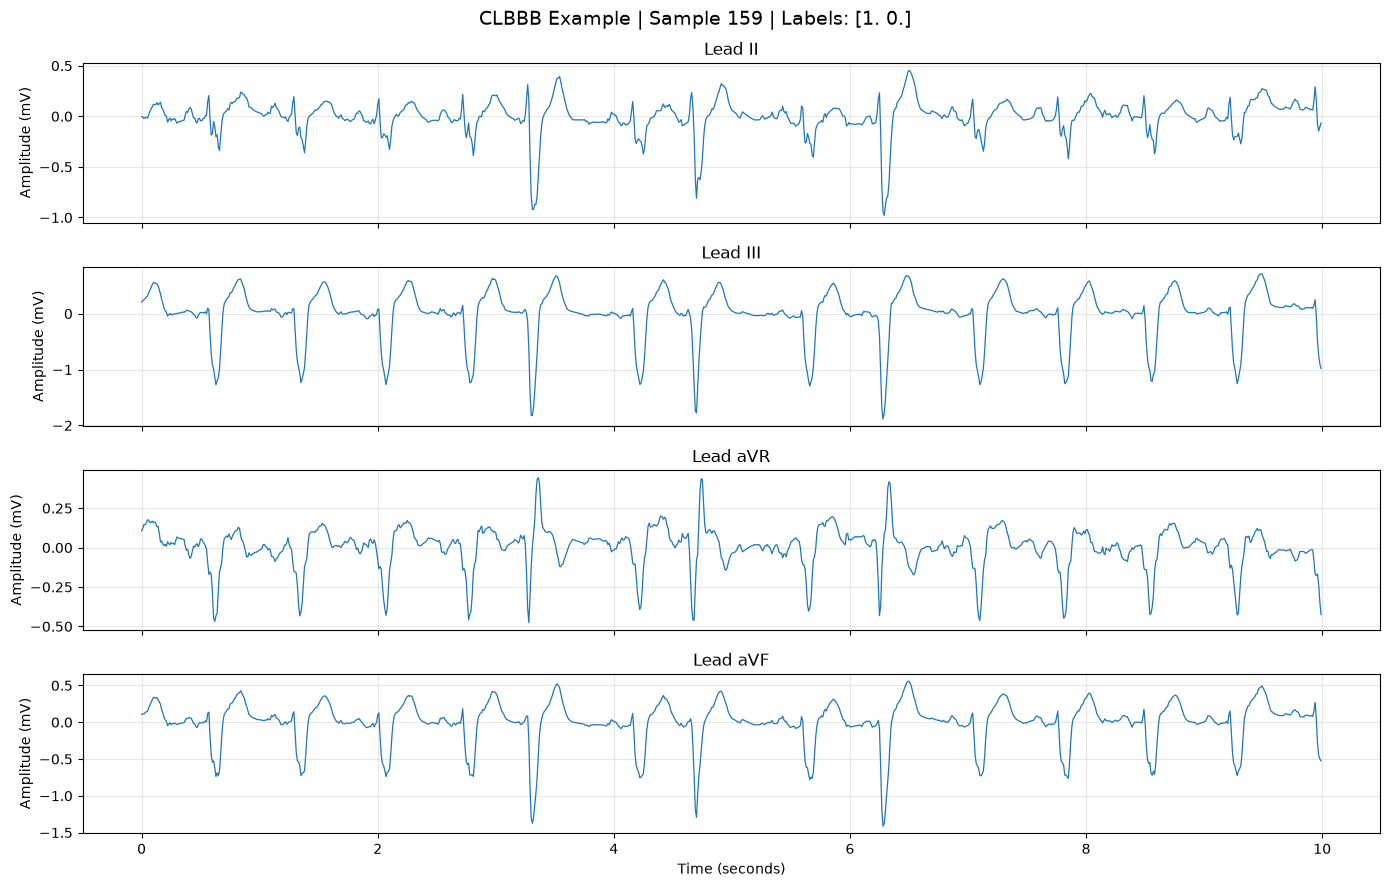

In [9]:
# Select the first CLBBB-positive training sample
clbbb_indices = np.where(y_train[:, 0] == 1)[0]
sample_idx = clbbb_indices[0]

sample_ecg = X_train[sample_idx]
sample_labels = y_train[sample_idx]

time_axis = np.arange(SIGNAL_LENGTH) / SAMPLING_RATE

fig, axes = plt.subplots(
    4, 1,
    figsize=(14, 9),
    sharex=True
)

for ax, (lead, idx) in zip(axes, LEAD_INDICES.items()):

    ax.plot(
        time_axis,
        sample_ecg[idx],
        linewidth=0.9
    )

    ax.set_title(f"Lead {lead}")
    ax.set_ylabel("Amplitude (mV)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")

fig.suptitle(
    f"CLBBB Example | Sample {sample_idx} | "
    f"Labels: {sample_labels}",
    fontsize=14
)

plt.tight_layout()
plt.show()

## 3. Single-Lead Dataset and DataLoader

Construct a reusable PyTorch Dataset that extracts
one specified ECG lead from the existing 12-lead arrays.

Each sample contains:
- Input: Single-lead ECG waveform (1, T)
- Target: Two binary labels [CLBBB, ILBBB]

Preserve the original dataset splits and avoid
duplicating waveform arrays.

In [10]:
class SingleLeadDataset(Dataset):

    def __init__(self, X, y, lead):

        if lead not in LEAD_INDICES:
            raise ValueError(f"Invalid target lead: {lead}")

        assert len(X) == len(y)
        assert X.ndim == 3
        assert X.shape[1] == len(ALL_LEADS)
        assert y.shape[1] == NUM_CLASSES

        self.X = X
        self.y = y

        self.lead = lead
        self.lead_idx = LEAD_INDICES[lead]

    def __len__(self):

        return len(self.y)

    def __getitem__(self, idx):

        # Extract only the specified lead
        waveform = np.array(
            self.X[idx, self.lead_idx:self.lead_idx + 1, :],
            dtype=np.float32,
            copy=True
        )

        # Preserve both output labels
        label = np.array(
            self.y[idx],
            dtype=np.float32,
            copy=True
        )

        return (
            torch.from_numpy(waveform),
            torch.from_numpy(label)
        )

In [11]:
for lead in TARGET_LEADS:

    dataset = SingleLeadDataset(
        X_train,
        y_train,
        lead=lead
    )

    waveform, label = dataset[0]

    print(f"Lead: {lead}")
    print(f"  Number of samples: {len(dataset)}")
    print(f"  Waveform shape: {waveform.shape}")
    print(f"  Label shape: {label.shape}")
    print(f"  Waveform dtype: {waveform.dtype}")
    print(f"  Label: {label}")
    print()

Lead: II
  Number of samples: 17418
  Waveform shape: torch.Size([1, 1000])
  Label shape: torch.Size([2])
  Waveform dtype: torch.float32
  Label: tensor([0., 0.])

Lead: III
  Number of samples: 17418
  Waveform shape: torch.Size([1, 1000])
  Label shape: torch.Size([2])
  Waveform dtype: torch.float32
  Label: tensor([0., 0.])

Lead: aVR
  Number of samples: 17418
  Waveform shape: torch.Size([1, 1000])
  Label shape: torch.Size([2])
  Waveform dtype: torch.float32
  Label: tensor([0., 0.])

Lead: aVF
  Number of samples: 17418
  Waveform shape: torch.Size([1, 1000])
  Label shape: torch.Size([2])
  Waveform dtype: torch.float32
  Label: tensor([0., 0.])



In [12]:
def create_dataloaders(lead, batch_size=BATCH_SIZE):

    train_dataset = SingleLeadDataset(
        X_train, y_train, lead
    )

    val_dataset = SingleLeadDataset(
        X_val, y_val, lead
    )

    test_dataset = SingleLeadDataset(
        X_test, y_test, lead
    )

    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return train_loader, val_loader, test_loader

In [13]:
for lead in TARGET_LEADS:

    train_loader, val_loader, test_loader = (
        create_dataloaders(lead)
    )

    X_batch, y_batch = next(iter(train_loader))

    assert X_batch.shape == (BATCH_SIZE, 1, SIGNAL_LENGTH)
    assert y_batch.shape == (BATCH_SIZE, NUM_CLASSES)

    assert torch.isfinite(X_batch).all()
    assert torch.isfinite(y_batch).all()

    print(f"Lead: {lead}")
    print(f"  Training batches: {len(train_loader)}")
    print(f"  Validation batches: {len(val_loader)}")
    print(f"  Test batches: {len(test_loader)}")
    print(f"  Input batch: {X_batch.shape}")
    print(f"  Target batch: {y_batch.shape}")
    print()

Lead: II
  Training batches: 545
  Validation batches: 69
  Test batches: 69
  Input batch: torch.Size([32, 1, 1000])
  Target batch: torch.Size([32, 2])

Lead: III
  Training batches: 545
  Validation batches: 69
  Test batches: 69
  Input batch: torch.Size([32, 1, 1000])
  Target batch: torch.Size([32, 2])

Lead: aVR
  Training batches: 545
  Validation batches: 69
  Test batches: 69
  Input batch: torch.Size([32, 1, 1000])
  Target batch: torch.Size([32, 2])

Lead: aVF
  Training batches: 545
  Validation batches: 69
  Test batches: 69
  Input batch: torch.Size([32, 1, 1000])
  Target batch: torch.Size([32, 2])



In [14]:
sample_idx = 159

for lead in TARGET_LEADS:

    dataset = SingleLeadDataset(
        X_train, y_train, lead
    )

    waveform, label = dataset[sample_idx]

    expected_waveform = X_train[
        sample_idx,
        LEAD_INDICES[lead],
        :
    ]

    expected_label = y_train[sample_idx]

    np.testing.assert_array_equal(
        waveform.numpy().squeeze(0),
        expected_waveform
    )

    np.testing.assert_array_equal(
        label.numpy(),
        expected_label
    )

    print(f"{lead}: Waveform and labels verified")

print("\nAll single-lead extraction checks passed.")

II: Waveform and labels verified
III: Waveform and labels verified
aVR: Waveform and labels verified
aVF: Waveform and labels verified

All single-lead extraction checks passed.


## 4. Baseline ResNet Architecture

Adapt the original Experiment 2 ResNet for single-lead
ECG classification.

Architecture:
- Input channels: 1
- Convolutional stem: 32 channels, kernel size 7
- Residual block 1: 32 → 32
- Residual block 2: 32 → 64
- Residual block 3: 64 → 128
- Global average pooling
- Linear classifier: 128 → 2

Preserve the original architecture except for the
number of input channels.

Output logits: CLBBB and ILBBB.

In [15]:
class ResidualBlock(nn.Module):

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size=7,
            stride=stride,
            padding=3
        )

        self.bn1 = nn.BatchNorm1d(out_channels)

        self.conv2 = nn.Conv1d(
            out_channels,
            out_channels,
            kernel_size=7,
            stride=1,
            padding=3
        )

        self.bn2 = nn.BatchNorm1d(out_channels)

        self.relu = nn.ReLU()

        # Match dimensions for residual addition
        if stride != 1 or in_channels != out_channels:

            self.shortcut = nn.Sequential(
                nn.Conv1d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride
                ),
                nn.BatchNorm1d(out_channels)
            )

        else:
            self.shortcut = nn.Identity()

    def forward(self, x):

        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity

        return self.relu(out)

In [16]:
class SingleLeadResNet(nn.Module):

    def __init__(self, in_channels=1, num_classes=2):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv1d(
                in_channels,
                32,
                kernel_size=7,
                padding=3
            ),
            nn.BatchNorm1d(32),
            nn.ReLU()
        )

        self.features = nn.Sequential(

            ResidualBlock(32, 32, stride=1),

            ResidualBlock(32, 64, stride=2),

            ResidualBlock(64, 128, stride=2)

        )

        self.pool = nn.AdaptiveAvgPool1d(1)

        self.classifier = nn.Linear(
            128,
            num_classes
        )

    def forward(self, x):

        x = self.stem(x)

        x = self.features(x)

        x = self.pool(x)

        x = x.squeeze(-1)

        logits = self.classifier(x)

        return logits

In [17]:
baseline_model = SingleLeadResNet(
    in_channels=NUM_INPUT_CHANNELS,
    num_classes=NUM_CLASSES
)

print(baseline_model)

total_params = sum(
    p.numel()
    for p in baseline_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in baseline_model.parameters()
    if p.requires_grad
)

print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

SingleLeadResNet(
  (stem): Sequential(
    (0): Conv1d(1, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (features): Sequential(
    (0): ResidualBlock(
      (conv1): Conv1d(32, 32, kernel_size=(7,), stride=(1,), padding=(3,))
      (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv1d(32, 32, kernel_size=(7,), stride=(1,), padding=(3,))
      (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU()
      (shortcut): Identity()
    )
    (1): ResidualBlock(
      (conv1): Conv1d(32, 64, kernel_size=(7,), stride=(2,), padding=(3,))
      (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv1d(64, 64, kernel_size=(7,), stride=(1,), padding=(3,))
      (bn2): BatchNorm1d(64, e

In [18]:
dummy_input = torch.randn(
    BATCH_SIZE,
    NUM_INPUT_CHANNELS,
    SIGNAL_LENGTH
)

baseline_model.eval()

with torch.no_grad():

    x = dummy_input
    print("Input:", x.shape)

    x = baseline_model.stem(x)
    print("Stem:", x.shape)

    for i, block in enumerate(baseline_model.features):

        x = block(x)

        print(f"Residual block {i + 1}:", x.shape)

    x = baseline_model.pool(x)
    print("Global pooling:", x.shape)

    x = x.squeeze(-1)
    print("Flattened:", x.shape)

    logits = baseline_model.classifier(x)
    print("Output logits:", logits.shape)

    probabilities = torch.sigmoid(logits)
    print("Output probabilities:", probabilities.shape)

assert logits.shape == (BATCH_SIZE, NUM_CLASSES)

Input: torch.Size([32, 1, 1000])
Stem: torch.Size([32, 32, 1000])
Residual block 1: torch.Size([32, 32, 1000])
Residual block 2: torch.Size([32, 64, 500])
Residual block 3: torch.Size([32, 128, 250])
Global pooling: torch.Size([32, 128, 1])
Flattened: torch.Size([32, 128])
Output logits: torch.Size([32, 2])
Output probabilities: torch.Size([32, 2])


In [19]:
# Use a temporary model for testing
test_model = SingleLeadResNet(
    in_channels=1,
    num_classes=2
).to(device)

test_model.train()

# Obtain a real Lead II training batch
train_loader, _, _ = create_dataloaders("II")

X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

# Temporary loss and optimizer
test_criterion = nn.BCEWithLogitsLoss()

test_optimizer = torch.optim.Adam(
    test_model.parameters(),
    lr=LEARNING_RATE
)

start_time = time.perf_counter()

# Forward pass
test_optimizer.zero_grad()

logits = test_model(X_batch)

loss = test_criterion(logits, y_batch)

# Backward pass
loss.backward()

assert torch.isfinite(logits).all().item()
assert torch.isfinite(loss).item()

for param in test_model.parameters():
    if param.grad is not None:
        assert torch.isfinite(param.grad).all().item()

# Parameter update
test_optimizer.step()

# Synchronize GPU operations for accurate timing
if device.type == "mps":
    torch.mps.synchronize()

elif device.type == "cuda":
    torch.cuda.synchronize()

elapsed_time = time.perf_counter() - start_time

print("Device:", device)
print("Input shape:", X_batch.shape)
print("Output shape:", logits.shape)
print(f"Loss: {loss.item():.6f}")
print(f"Training step time: {elapsed_time:.4f} seconds")

print("\nForward pass: Passed")
print("Backward pass: Passed")
print("Parameter update: Passed")

# Remove temporary model and optimizer
del test_model, test_optimizer, logits, loss
del X_batch, y_batch

if device.type == "mps":
    torch.mps.empty_cache()

Device: mps
Input shape: torch.Size([32, 1, 1000])
Output shape: torch.Size([32, 2])
Loss: 0.843473
Training step time: 3.9893 seconds

Forward pass: Passed
Backward pass: Passed
Parameter update: Passed


## 5. Improved Single-Lead ResNet Architecture

Investigate three targeted modifications to the
baseline ResNet:

1. Multi-scale convolutional stem
   - Kernel sizes: 5, 11, 21
   - Output channels: 8, 12, 12
   - Total output channels: 32

2. Combined global average and max pooling
   - Concatenate both pooled representations
   - Increase feature dimension from 128 to 256

3. Dropout regularization
   - Dropout probability: 0.2

Preserve:
- Three original residual blocks
- Single-lead input
- Two independent output logits (CLBBB and ILBBB)
- Original baseline architecture as a separate model

Compare both architectures using identical data splits
and training configurations.

In [20]:
class MultiScaleStem(nn.Module):

    def __init__(self, in_channels=1):
        super().__init__()

        # Small temporal scale
        self.branch_small = nn.Sequential(
            nn.Conv1d(
                in_channels,
                8,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm1d(8),
            nn.ReLU()
        )

        # Medium temporal scale
        self.branch_medium = nn.Sequential(
            nn.Conv1d(
                in_channels,
                12,
                kernel_size=11,
                padding=5
            ),
            nn.BatchNorm1d(12),
            nn.ReLU()
        )

        # Large temporal scale
        self.branch_large = nn.Sequential(
            nn.Conv1d(
                in_channels,
                12,
                kernel_size=21,
                padding=10
            ),
            nn.BatchNorm1d(12),
            nn.ReLU()
        )

    def forward(self, x):

        small = self.branch_small(x)
        medium = self.branch_medium(x)
        large = self.branch_large(x)

        # Concatenate along the channel dimension
        out = torch.cat(
            [small, medium, large],
            dim=1
        )

        return out

In [21]:
class ImprovedSingleLeadResNet(nn.Module):

    def __init__(
        self,
        in_channels=1,
        num_classes=2,
        dropout=0.2
    ):
        super().__init__()

        # Improvement 1: Multi-scale stem
        self.stem = MultiScaleStem(
            in_channels=in_channels
        )

        # Reuse original residual blocks
        self.features = nn.Sequential(

            ResidualBlock(32, 32, stride=1),

            ResidualBlock(32, 64, stride=2),

            ResidualBlock(64, 128, stride=2)

        )

        # Improvement 2: Dual pooling
        self.avg_pool = nn.AdaptiveAvgPool1d(1)

        self.max_pool = nn.AdaptiveMaxPool1d(1)

        # Improvement 3: Regularization
        self.dropout = nn.Dropout(p=dropout)

        # Two independent output logits
        self.classifier = nn.Linear(
            256,
            num_classes
        )

    def forward(self, x):

        x = self.stem(x)

        x = self.features(x)

        avg_features = self.avg_pool(x).squeeze(-1)

        max_features = self.max_pool(x).squeeze(-1)

        # Combine average and maximum activations
        x = torch.cat(
            [avg_features, max_features],
            dim=1
        )

        x = self.dropout(x)

        logits = self.classifier(x)

        return logits

In [22]:
baseline_model = SingleLeadResNet(
    in_channels=1,
    num_classes=2
)

improved_model = ImprovedSingleLeadResNet(
    in_channels=1,
    num_classes=2,
    dropout=0.2
)

baseline_params = sum(
    p.numel()
    for p in baseline_model.parameters()
    if p.requires_grad
)

improved_params = sum(
    p.numel()
    for p in improved_model.parameters()
    if p.requires_grad
)

parameter_increase = (
    (improved_params - baseline_params)
    / baseline_params
    * 100
)

parameter_comparison = pd.DataFrame({

    "Architecture": [
        "Baseline ResNet",
        "Improved ResNet"
    ],

    "Trainable Parameters": [
        baseline_params,
        improved_params
    ]

})

display(parameter_comparison)

print(f"Additional parameters: "
      f"{improved_params - baseline_params:,}")

print(f"Parameter increase: "
      f"{parameter_increase:.4f}%")

,Architecture,Trainable Parameters
0,Baseline ResNet,242114
1,Improved ResNet,242570


Additional parameters: 456
Parameter increase: 0.1883%


In [23]:
dummy_input = torch.randn(
    BATCH_SIZE,
    NUM_INPUT_CHANNELS,
    SIGNAL_LENGTH
)

improved_model.eval()

with torch.no_grad():

    x = dummy_input
    print("Input:", x.shape)

    x = improved_model.stem(x)
    print("Multi-scale stem:", x.shape)

    for i, block in enumerate(improved_model.features):

        x = block(x)

        print(f"Residual block {i + 1}:", x.shape)

    avg_features = improved_model.avg_pool(x).squeeze(-1)

    max_features = improved_model.max_pool(x).squeeze(-1)

    print("Average pooled:", avg_features.shape)
    print("Max pooled:", max_features.shape)

    combined_features = torch.cat(
        [avg_features, max_features],
        dim=1
    )

    print("Combined features:", combined_features.shape)

    x = improved_model.dropout(combined_features)

    print("After dropout:", x.shape)

    logits = improved_model.classifier(x)

    print("Output logits:", logits.shape)

    probabilities = torch.sigmoid(logits)

    print("Output probabilities:", probabilities.shape)

assert logits.shape == (BATCH_SIZE, NUM_CLASSES)

Input: torch.Size([32, 1, 1000])
Multi-scale stem: torch.Size([32, 32, 1000])
Residual block 1: torch.Size([32, 32, 1000])
Residual block 2: torch.Size([32, 64, 500])
Residual block 3: torch.Size([32, 128, 250])
Average pooled: torch.Size([32, 128])
Max pooled: torch.Size([32, 128])
Combined features: torch.Size([32, 256])
After dropout: torch.Size([32, 256])
Output logits: torch.Size([32, 2])
Output probabilities: torch.Size([32, 2])


In [24]:
def synchronize_device(device):

    if device.type == "mps":
        torch.mps.synchronize()

    elif device.type == "cuda":
        torch.cuda.synchronize()


def test_architecture(model_class, architecture_name):

    model = model_class(
        in_channels=1,
        num_classes=2
    ).to(device)

    model.train()

    train_loader, _, _ = create_dataloaders("II")

    X_batch, y_batch = next(iter(train_loader))

    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    def training_step():

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        loss.backward()

        optimizer.step()

        return logits, loss

    # GPU warm-up
    for _ in range(3):
        logits, loss = training_step()

    synchronize_device(device)

    # Timed training steps
    num_steps = 10

    start_time = time.perf_counter()

    for _ in range(num_steps):
        logits, loss = training_step()

    synchronize_device(device)

    elapsed_time = time.perf_counter() - start_time

    avg_step_time = elapsed_time / num_steps

    # Integrity checks
    assert logits.shape == (BATCH_SIZE, NUM_CLASSES)

    assert torch.isfinite(logits).all().item()

    assert torch.isfinite(loss).item()

    for param in model.parameters():

        if param.grad is not None:

            assert torch.isfinite(param.grad).all().item()

        assert torch.isfinite(param).all().item()

    results = {

        "Architecture": architecture_name,

        "Device": str(device),

        "Parameters": sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        ),

        "Output Shape": str(tuple(logits.shape)),

        "Loss": loss.item(),

        "Average Step Time (s)": avg_step_time,

        "Status": "Passed"

    }

    del model, optimizer, logits, loss
    del X_batch, y_batch

    if device.type == "mps":
        torch.mps.empty_cache()

    elif device.type == "cuda":
        torch.cuda.empty_cache()

    return results

In [25]:
architecture_tests = []

architecture_tests.append(

    test_architecture(
        SingleLeadResNet,
        "Baseline ResNet"
    )

)

architecture_tests.append(

    test_architecture(
        ImprovedSingleLeadResNet,
        "Improved ResNet"
    )

)

architecture_test_results = pd.DataFrame(
    architecture_tests
)

display(architecture_test_results.round(4))

,Architecture,Device,Parameters,Output Shape,Loss,Average Step Time (s),Status
0,Baseline ResNet,mps,242114,"(32, 2)",0.1583,0.0231,Passed
1,Improved ResNet,mps,242570,"(32, 2)",0.0028,0.0240,Passed


In [26]:
ARCHITECTURES = {

    "baseline": SingleLeadResNet,

    "improved": ImprovedSingleLeadResNet

}


def build_model(architecture):

    if architecture not in ARCHITECTURES:

        raise ValueError(
            f"Unknown architecture: {architecture}"
        )

    model_class = ARCHITECTURES[architecture]

    model = model_class(
        in_channels=NUM_INPUT_CHANNELS,
        num_classes=NUM_CLASSES
    )

    return model

## 6. Shared Training Procedure

Implement a unified training and validation pipeline
for baseline and improved single-lead ResNet models.

Training configuration:
- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 32
- Maximum epochs: 30
- Early stopping patience: 7
- Loss: Weighted BCEWithLogitsLoss
- Checkpoint selection: Minimum validation loss
- Random seed: 42

Monitor:
- Training loss
- Validation loss
- Per-label validation AUROC
- Per-label validation AUPRC

Save independent checkpoints and training histories
for each lead and architecture.

Preserve the held-out test set for final evaluation.

In [27]:
def calculate_pos_weights(y):

    positives = np.asarray(y).sum(axis=0)

    negatives = len(y) - positives

    if np.any(positives == 0):
        raise ValueError(
            "At least one target has no positive samples."
        )

    pos_weights = negatives / positives

    return torch.tensor(
        pos_weights,
        dtype=torch.float32
    )


pos_weights = calculate_pos_weights(y_train)

for label, weight in zip(LABELS, pos_weights):

    print(f"{label}: {weight.item():.4f}")


criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weights.to(device)
)

print("\nLoss function:", criterion)
print("Positive weights:", criterion.pos_weight)

CLBBB: 39.6963
ILBBB: 279.9355

Loss function: BCEWithLogitsLoss()
Positive weights: tensor([ 39.6963, 279.9355], device='mps:0')


In [28]:
def set_seed(seed=SEED):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(seed)

    if torch.backends.mps.is_available():

        torch.mps.manual_seed(seed)


set_seed(SEED)

print(f"Random seed configured: {SEED}")

Random seed configured: 42


In [29]:
def calculate_metrics(y_true, y_scores):

    metrics = {}

    for i, label in enumerate(LABELS):

        truth = y_true[:, i]

        scores = y_scores[:, i]

        # AUROC requires both positive and negative samples
        if len(np.unique(truth)) == 2:

            auroc = roc_auc_score(
                truth,
                scores
            )

        else:

            auroc = np.nan

        # Average precision requires positive samples
        if truth.sum() > 0:

            auprc = average_precision_score(
                truth,
                scores
            )

        else:

            auprc = np.nan

        metrics[f"{label}_AUROC"] = auroc

        metrics[f"{label}_AUPRC"] = auprc

    return metrics

In [30]:
rng = np.random.default_rng(SEED)

random_scores = rng.random(y_val.shape)

random_metrics = calculate_metrics(
    np.asarray(y_val),
    random_scores
)

display(
    pd.DataFrame([random_metrics]).round(4)
)

,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC
0,0.4783,0.0238,0.4355,0.0033


In [31]:
def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    device
):

    model.train()

    total_loss = torch.zeros(
        (),
        device=device
    )

    total_samples = 0

    for X_batch, y_batch in dataloader:

        X_batch = X_batch.to(device)

        y_batch = y_batch.to(device)

        # Reset gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        logits = model(X_batch)

        # Weighted binary cross-entropy
        loss = criterion(logits, y_batch)

        # Backward pass
        loss.backward()

        # Parameter update
        optimizer.step()

        # Accumulate sample-weighted loss
        batch_size = X_batch.size(0)

        total_loss += loss.detach() * batch_size

        total_samples += batch_size

    epoch_loss = (
        total_loss / total_samples
    ).item()

    if not np.isfinite(epoch_loss):

        raise RuntimeError(
            "Non-finite training loss detected."
        )

    return epoch_loss

In [32]:
def evaluate_model(
    model,
    dataloader,
    criterion,
    device
):

    model.eval()

    total_loss = torch.zeros(
        (),
        device=device
    )

    total_samples = 0

    all_targets = []

    all_scores = []

    with torch.no_grad():

        for X_batch, y_batch in dataloader:

            X_batch = X_batch.to(device)

            y_batch = y_batch.to(device)

            # Forward pass
            logits = model(X_batch)

            loss = criterion(logits, y_batch)

            # Convert logits into prediction scores
            scores = torch.sigmoid(logits)

            batch_size = X_batch.size(0)

            total_loss += loss.detach() * batch_size

            total_samples += batch_size

            # Store detached predictions and labels
            all_targets.append(y_batch.detach())

            all_scores.append(scores.detach())

    avg_loss = (
        total_loss / total_samples
    ).item()

    y_true = torch.cat(
        all_targets,
        dim=0
    ).cpu().numpy()

    y_scores = torch.cat(
        all_scores,
        dim=0
    ).cpu().numpy()

    if not np.isfinite(avg_loss):

        raise RuntimeError(
            "Non-finite evaluation loss detected."
        )

    if not np.isfinite(y_scores).all():

        raise RuntimeError(
            "Non-finite predictions detected."
        )

    metrics = calculate_metrics(
        y_true,
        y_scores
    )

    return avg_loss, metrics, y_true, y_scores

In [33]:
import json


def get_run_directory(
    architecture,
    lead,
    representation="full_ecg"
):

    if architecture not in ARCHITECTURES:

        raise ValueError(
            f"Invalid architecture: {architecture}"
        )

    if lead not in TARGET_LEADS:

        raise ValueError(
            f"Invalid lead: {lead}"
        )

    run_dir = (
        RESULTS_DIR
        / representation
        / architecture
        / lead
    )

    run_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    return run_dir

In [34]:
for architecture in ARCHITECTURES:

    for lead in TARGET_LEADS:

        run_dir = get_run_directory(
            architecture,
            lead
        )

        print(run_dir)

results/experiment3/full_ecg/baseline/II
results/experiment3/full_ecg/baseline/III
results/experiment3/full_ecg/baseline/aVR
results/experiment3/full_ecg/baseline/aVF
results/experiment3/full_ecg/improved/II
results/experiment3/full_ecg/improved/III
results/experiment3/full_ecg/improved/aVR
results/experiment3/full_ecg/improved/aVF


In [85]:
def train_model(
    architecture,
    lead,
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE,
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    seed=SEED,
    representation="full_ecg"
):

    # -----------------------------------
    # 1. Reproducibility
    # -----------------------------------

    set_seed(seed)

    # -----------------------------------
    # 2. Result directory
    # -----------------------------------

    run_dir = get_run_directory(
        architecture,
        lead,
        representation=representation
    )

    checkpoint_path = run_dir / "best_model.pt"

    # -----------------------------------
    # 3. DataLoaders
    # -----------------------------------

    train_loader, val_loader, _ = create_dataloaders(
        lead,
        batch_size=batch_size,
        representation=representation
    )

    # Reset shuffle seed for this run
    train_loader.generator.manual_seed(seed)

    # -----------------------------------
    # 4. Initialize model
    # -----------------------------------

    model = build_model(
        architecture
    ).to(device)

    # -----------------------------------
    # 5. Loss and optimizer
    # -----------------------------------

    run_pos_weights = calculate_pos_weights(
        train_loader.dataset.y
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=run_pos_weights.to(device)
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    # -----------------------------------
    # 6. Save configuration
    # -----------------------------------

    config = {

        "architecture": architecture,

        "lead": lead,

        "representation": representation,

        "labels": LABELS,

        "seed": seed,

        "batch_size": batch_size,

        "learning_rate": learning_rate,

        "max_epochs": max_epochs,

        "patience": patience,

        "optimizer": "Adam",

        "weight_decay": 0,

        "loss": "Weighted BCEWithLogitsLoss",

        "positive_weights": run_pos_weights.tolist(),

        "checkpoint_selection": "validation_loss",

        "device": str(device),

        "parameters": sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )

    }

    with open(run_dir / "config.json", "w") as f:

        json.dump(config, f, indent=4)

    # -----------------------------------
    # 7. Training state
    # -----------------------------------

    best_val_loss = float("inf")

    best_epoch = None

    epochs_without_improvement = 0

    history = []

    print("=" * 70)

    print(f"Architecture: {architecture}")
    print(f"Lead: {lead}")
    print(f"Device: {device}")
    print(f"Parameters: {config['parameters']:,}")
    print(f"Results: {run_dir}")

    print("=" * 70)

    total_start_time = time.perf_counter()

    # -----------------------------------
    # 8. Epoch loop
    # -----------------------------------

    for epoch in range(1, max_epochs + 1):

        synchronize_device(device)

        epoch_start = time.perf_counter()

        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        val_loss, val_metrics, _, _ = evaluate_model(
            model,
            val_loader,
            criterion,
            device
        )

        synchronize_device(device)

        epoch_time = (
            time.perf_counter() - epoch_start
        )

        # Store history
        epoch_record = {

            "epoch": epoch,

            "train_loss": train_loss,

            "val_loss": val_loss,

            **val_metrics,

            "epoch_time_seconds": epoch_time

        }

        history.append(epoch_record)

        # -----------------------------------
        # 9. Checkpoint selection
        # -----------------------------------

        improved = val_loss < best_val_loss

        if improved:

            best_val_loss = val_loss

            best_epoch = epoch

            epochs_without_improvement = 0

            torch.save(

                {
                    "model_state_dict": model.state_dict(),

                    "epoch": epoch,

                    "val_loss": val_loss,

                    "val_metrics": val_metrics,

                    "pos_weight": run_pos_weights,

                    "architecture": architecture,

                    "lead": lead,

                    "seed": seed
                },

                checkpoint_path

            )

        else:

            epochs_without_improvement += 1

        # Save history after every epoch
        pd.DataFrame(history).to_csv(

            run_dir / "training_history.csv",

            index=False

        )

        # -----------------------------------
        # 10. Progress reporting
        # -----------------------------------

        print(

            f"Epoch {epoch:02d}/{max_epochs} | "

            f"Train: {train_loss:.4f} | "

            f"Val: {val_loss:.4f} | "

            f"Time: {epoch_time:.1f}s"

        )

        print(

            f"  CLBBB AUROC: "
            f"{val_metrics['CLBBB_AUROC']:.4f} | "

            f"AUPRC: "
            f"{val_metrics['CLBBB_AUPRC']:.4f}"

        )

        print(

            f"  ILBBB AUROC: "
            f"{val_metrics['ILBBB_AUROC']:.4f} | "

            f"AUPRC: "
            f"{val_metrics['ILBBB_AUPRC']:.4f}"

        )

        if improved:

            print("  Saved new best model")

        else:

            print(

                f"  No improvement: "
                f"{epochs_without_improvement}/{patience}"

            )

        # -----------------------------------
        # 11. Early stopping
        # -----------------------------------

        if epochs_without_improvement >= patience:

            print("\nEarly stopping triggered.")

            break

    # -----------------------------------
    # 12. Restore best checkpoint
    # -----------------------------------

    checkpoint = torch.load(

        checkpoint_path,

        map_location=device,

        weights_only=True

    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    # -----------------------------------
    # 13. Evaluate best checkpoint
    # -----------------------------------

    val_loss, val_metrics, y_true, y_scores = (
        evaluate_model(
            model,
            val_loader,
            criterion,
            device
        )
    )

    total_training_time = (
        time.perf_counter() - total_start_time
    )

    summary = {

        "architecture": architecture,

        "lead": lead,

        "representation": "full_ecg",

        "best_epoch": best_epoch,

        "epochs_trained": len(history),

        "best_val_loss": val_loss,

        **val_metrics,

        "training_time_seconds": total_training_time

    }

    # -----------------------------------
    # 14. Save final validation results
    # -----------------------------------

    history_df = pd.DataFrame(history)

    summary_df = pd.DataFrame([summary])

    summary_df.to_csv(

        run_dir / "validation_metrics.csv",

        index=False

    )

    np.save(

        run_dir / "validation_scores.npy",

        y_scores

    )

    np.save(

        run_dir / "validation_targets.npy",

        y_true

    )

    print("\n" + "=" * 70)

    print("Training complete.")

    print(f"Best epoch: {best_epoch}")

    print(f"Best validation loss: {val_loss:.4f}")

    print(

        f"Total training time: "
        f"{total_training_time / 60:.2f} minutes"

    )

    print("=" * 70)

    # Release GPU memory
    del model, optimizer, checkpoint, criterion

    if device.type == "mps":

        torch.mps.empty_cache()

    elif device.type == "cuda":

        torch.cuda.empty_cache()

    return history_df, summary_df

In [36]:
from torch.utils.data import Subset

smoke_test_results = []

for architecture in ARCHITECTURES:

    set_seed(SEED)

    model = build_model(
        architecture
    ).to(device)

    train_loader, val_loader, _ = (
        create_dataloaders("II")
    )

    # Use only 64 training samples
    small_dataset = Subset(

        train_loader.dataset,

        range(64)

    )

    small_loader = DataLoader(

        small_dataset,

        batch_size=BATCH_SIZE,

        shuffle=False

    )

    smoke_criterion = nn.BCEWithLogitsLoss(

        pos_weight=pos_weights.to(device)

    )

    optimizer = torch.optim.Adam(

        model.parameters(),

        lr=LEARNING_RATE

    )

    smoke_train_loss = train_one_epoch(

        model,

        small_loader,

        smoke_criterion,

        optimizer,

        device

    )

    smoke_val_loss, smoke_metrics, targets, scores = (
        evaluate_model(

            model,

            val_loader,

            smoke_criterion,

            device

        )
    )

    assert scores.shape == y_val.shape

    assert targets.shape == y_val.shape

    np.testing.assert_array_equal(
        targets,
        np.asarray(y_val)
    )

    smoke_test_results.append({

        "Architecture": architecture,

        "Training Loss": smoke_train_loss,

        "Validation Loss": smoke_val_loss,

        "Prediction Shape": str(scores.shape),

        **smoke_metrics,

        "Status": "Passed"

    })

    del model, optimizer, smoke_criterion

    if device.type == "mps":

        torch.mps.empty_cache()


display(

    pd.DataFrame(smoke_test_results).round(4)

)

,Architecture,Training Loss,Validation Loss,Prediction Shape,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC,Status
0,baseline,0.5211,1.3352,"(2183, 2)",0.6131,0.0552,0.4269,0.0033,Passed
1,improved,0.4260,1.3334,"(2183, 2)",0.6168,0.0410,0.6687,0.0119,Passed


## 7. Full ECG Model Training

Train eight independent single-lead models using
the full 10-second ECG representation.

### Baseline Models
- Lead II
- Lead III
- Lead aVR
- Lead aVF

### Improved Models
- Lead II
- Lead III
- Lead aVR
- Lead aVF

All models use identical data splits, class weights,
optimizer settings, and early stopping criteria.

Select checkpoints based on minimum validation loss.

Do not evaluate the held-out test set during training
or architecture selection.

In [37]:
baseline_II_history, baseline_II_summary = train_model(

    architecture="baseline",

    lead="II",

    max_epochs=MAX_EPOCHS,

    patience=PATIENCE,

    learning_rate=LEARNING_RATE,

    batch_size=BATCH_SIZE,

    seed=SEED

)

display(baseline_II_summary.round(4))

Architecture: baseline
Lead: II
Device: mps
Parameters: 242,114
Results: results/experiment3/full_ecg/baseline/II
Epoch 01/30 | Train: 0.7550 | Val: 0.7933 | Time: 19.1s
  CLBBB AUROC: 0.9709 | AUPRC: 0.4695
  ILBBB AUROC: 0.8407 | AUPRC: 0.0231
  Saved new best model
Epoch 02/30 | Train: 0.6056 | Val: 0.7553 | Time: 18.2s
  CLBBB AUROC: 0.9713 | AUPRC: 0.5579
  ILBBB AUROC: 0.8373 | AUPRC: 0.0209
  Saved new best model
Epoch 03/30 | Train: 0.6130 | Val: 0.7539 | Time: 18.8s
  CLBBB AUROC: 0.9630 | AUPRC: 0.4551
  ILBBB AUROC: 0.8453 | AUPRC: 0.0274
  Saved new best model
Epoch 04/30 | Train: 0.5436 | Val: 0.7187 | Time: 15.7s
  CLBBB AUROC: 0.9650 | AUPRC: 0.5221
  ILBBB AUROC: 0.8533 | AUPRC: 0.0235
  Saved new best model
Epoch 05/30 | Train: 0.5433 | Val: 0.7668 | Time: 18.8s
  CLBBB AUROC: 0.9685 | AUPRC: 0.5422
  ILBBB AUROC: 0.8447 | AUPRC: 0.0254
  No improvement: 1/7
Epoch 06/30 | Train: 0.5315 | Val: 0.8279 | Time: 18.7s
  CLBBB AUROC: 0.9651 | AUPRC: 0.4538
  ILBBB AUROC: 0.8

,architecture,lead,representation,best_epoch,epochs_trained,best_val_loss,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC,training_time_seconds
0,baseline,II,full_ecg,9,16,0.6737,0.9708,0.6055,0.8754,0.028,278.8476


In [38]:
def plot_training_history(
    history,
    architecture,
    lead,
    best_epoch
):

    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 5)
    )

    epochs = history["epoch"]

    # -----------------------------------
    # 1. Training and validation loss
    # -----------------------------------

    axes[0].plot(
        epochs,
        history["train_loss"],
        label="Training loss"
    )

    axes[0].plot(
        epochs,
        history["val_loss"],
        label="Validation loss"
    )

    axes[0].set_title("Weighted BCE Loss")
    axes[0].set_ylabel("Loss")

    # -----------------------------------
    # 2. Validation AUROC
    # -----------------------------------

    axes[1].plot(
        epochs,
        history["CLBBB_AUROC"],
        label="CLBBB"
    )

    axes[1].plot(
        epochs,
        history["ILBBB_AUROC"],
        label="ILBBB"
    )

    axes[1].axhline(
        0.5,
        linestyle=":",
        color="gray",
        label="Random ranking"
    )

    axes[1].set_title("Validation AUROC")
    axes[1].set_ylabel("AUROC")
    axes[1].set_ylim(0, 1.02)

    # -----------------------------------
    # 3. Validation AUPRC
    # -----------------------------------

    axes[2].plot(
        epochs,
        history["CLBBB_AUPRC"],
        label="CLBBB"
    )

    axes[2].plot(
        epochs,
        history["ILBBB_AUPRC"],
        label="ILBBB"
    )

    axes[2].set_title("Validation AUPRC")
    axes[2].set_ylabel("AUPRC")
    axes[2].set_ylim(0, 1.02)

    # -----------------------------------
    # Shared plot formatting
    # -----------------------------------

    for ax in axes:

        ax.axvline(
            best_epoch,
            linestyle="--",
            color="black",
            alpha=0.6,
            label=f"Best epoch: {best_epoch}"
        )

        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.3)

    fig.suptitle(
        f"{architecture.capitalize()} ResNet | Lead {lead}",
        fontsize=15
    )

    plt.tight_layout()

    run_dir = get_run_directory(
        architecture,
        lead
    )

    fig.savefig(
        run_dir / "training_curves.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

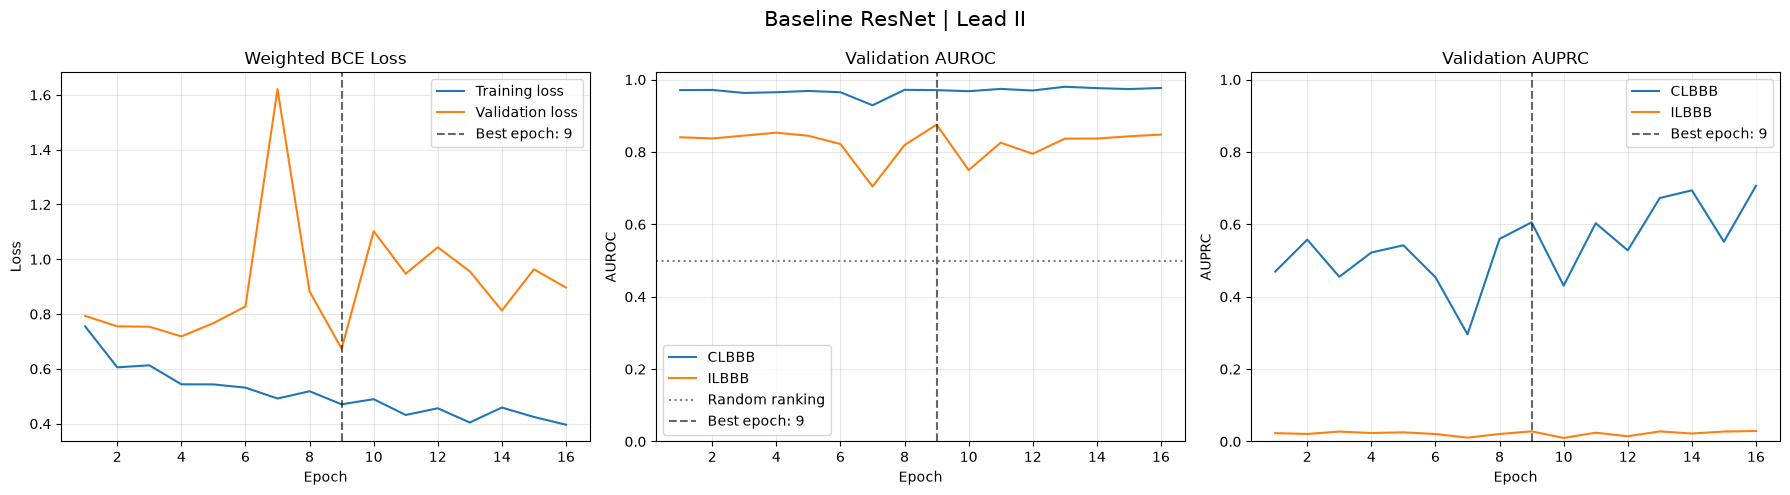

In [39]:
best_epoch = int(
    baseline_II_summary.iloc[0]["best_epoch"]
)

plot_training_history(

    history=baseline_II_history,

    architecture="baseline",

    lead="II",

    best_epoch=best_epoch

)

In [41]:
run_dir = get_run_directory(
    architecture="baseline",
    lead="II"
)

expected_files = [

    "best_model.pt",

    "config.json",

    "training_history.csv",

    "validation_metrics.csv",

    "validation_scores.npy",

    "validation_targets.npy",

    "training_curves.png"

]

for filename in expected_files:

    path = run_dir / filename

    assert path.exists(), f"Missing file: {path}"

    print(f"Found: {filename}")

print("\nAll training artifacts verified.")

Found: best_model.pt
Found: config.json
Found: training_history.csv
Found: validation_metrics.csv
Found: validation_scores.npy
Found: validation_targets.npy
Found: training_curves.png

All training artifacts verified.


In [42]:
checkpoint = torch.load(

    run_dir / "best_model.pt",

    map_location="cpu",

    weights_only=True

)

print("Architecture:", checkpoint["architecture"])

print("Lead:", checkpoint["lead"])

print("Seed:", checkpoint["seed"])

print("Best epoch:", checkpoint["epoch"])

print("Best validation loss:", checkpoint["val_loss"])

print("\nValidation metrics:")

display(

    pd.DataFrame(
        [checkpoint["val_metrics"]]
    ).round(4)

)

assert checkpoint["architecture"] == "baseline"

assert checkpoint["lead"] == "II"

assert checkpoint["epoch"] == best_epoch

print("\nCheckpoint successfully verified.")

Architecture: baseline
Lead: II
Seed: 42
Best epoch: 9
Best validation loss: 0.6737348437309265

Validation metrics:


,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC
0,0.9708,0.6055,0.8754,0.028



Checkpoint successfully verified.


In [43]:
training_configs = [

    {
        "architecture": architecture,
        "lead": lead
    }

    for architecture in ARCHITECTURES

    for lead in TARGET_LEADS

]

display(pd.DataFrame(training_configs))

,architecture,lead
0,baseline,II
1,baseline,III
2,baseline,aVR
3,baseline,aVF
4,improved,II
5,improved,III
6,improved,aVR
7,improved,aVF


In [44]:
def is_training_complete(architecture, lead):

    run_dir = get_run_directory(
        architecture,
        lead
    )

    required_files = [
        "best_model.pt",
        "config.json",
        "training_history.csv",
        "validation_metrics.csv",
        "validation_scores.npy",
        "validation_targets.npy"
    ]

    return all(
        (run_dir / filename).exists()
        for filename in required_files
    )


training_status = []

for config in training_configs:

    architecture = config["architecture"]
    lead = config["lead"]

    completed = is_training_complete(
        architecture,
        lead
    )

    training_status.append({

        "Architecture": architecture,

        "Lead": lead,

        "Status": (
            "Completed"
            if completed
            else "Pending"
        )

    })


display(pd.DataFrame(training_status))

,Architecture,Lead,Status
0,baseline,II,Completed
1,baseline,III,Pending
2,baseline,aVR,Pending
3,baseline,aVF,Pending
4,improved,II,Pending
5,improved,III,Pending
6,improved,aVR,Pending
7,improved,aVF,Pending


Skipping completed model: baseline | Lead II
Architecture: baseline
Lead: III
Device: mps
Parameters: 242,114
Results: results/experiment3/full_ecg/baseline/III
Epoch 01/30 | Train: 1.0691 | Val: 0.9357 | Time: 18.4s
  CLBBB AUROC: 0.8969 | AUPRC: 0.2265
  ILBBB AUROC: 0.8476 | AUPRC: 0.0321
  Saved new best model
Epoch 02/30 | Train: 0.9281 | Val: 0.9638 | Time: 15.6s
  CLBBB AUROC: 0.9021 | AUPRC: 0.1935
  ILBBB AUROC: 0.7679 | AUPRC: 0.0174
  No improvement: 1/7
Epoch 03/30 | Train: 0.8279 | Val: 0.9057 | Time: 15.6s
  CLBBB AUROC: 0.9288 | AUPRC: 0.3052
  ILBBB AUROC: 0.7724 | AUPRC: 0.0169
  Saved new best model
Epoch 04/30 | Train: 0.8020 | Val: 0.8072 | Time: 17.7s
  CLBBB AUROC: 0.9423 | AUPRC: 0.3489
  ILBBB AUROC: 0.8024 | AUPRC: 0.0236
  Saved new best model
Epoch 05/30 | Train: 0.7564 | Val: 0.8180 | Time: 18.6s
  CLBBB AUROC: 0.9443 | AUPRC: 0.3441
  ILBBB AUROC: 0.8386 | AUPRC: 0.0301
  No improvement: 1/7
Epoch 06/30 | Train: 0.6970 | Val: 0.9741 | Time: 18.6s
  CLBBB AU

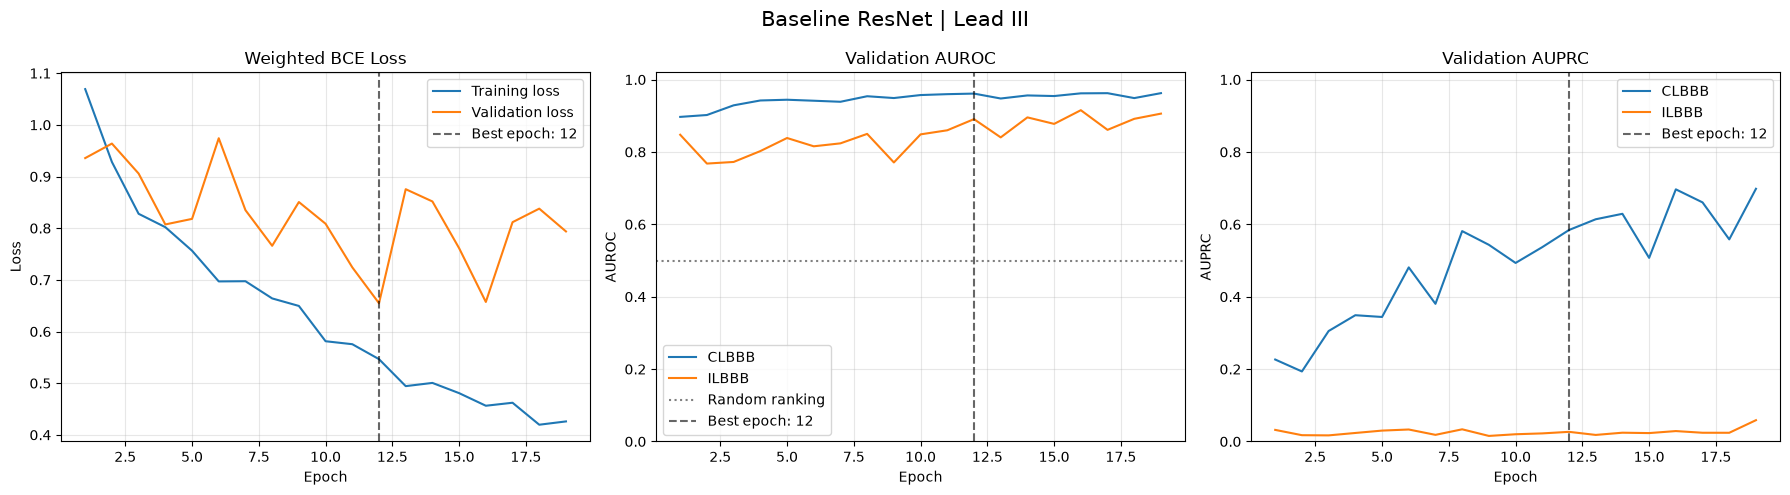

Architecture: baseline
Lead: aVR
Device: mps
Parameters: 242,114
Results: results/experiment3/full_ecg/baseline/aVR
Epoch 01/30 | Train: 0.6392 | Val: 0.6479 | Time: 16.7s
  CLBBB AUROC: 0.9633 | AUPRC: 0.4345
  ILBBB AUROC: 0.9064 | AUPRC: 0.0586
  Saved new best model
Epoch 02/30 | Train: 0.5009 | Val: 0.5842 | Time: 15.9s
  CLBBB AUROC: 0.9818 | AUPRC: 0.8143
  ILBBB AUROC: 0.9047 | AUPRC: 0.0762
  Saved new best model
Epoch 03/30 | Train: 0.4579 | Val: 0.6524 | Time: 15.9s
  CLBBB AUROC: 0.9760 | AUPRC: 0.6809
  ILBBB AUROC: 0.8898 | AUPRC: 0.0495
  No improvement: 1/7
Epoch 04/30 | Train: 0.4442 | Val: 0.5591 | Time: 15.9s
  CLBBB AUROC: 0.9823 | AUPRC: 0.7769
  ILBBB AUROC: 0.8975 | AUPRC: 0.0804
  Saved new best model
Epoch 05/30 | Train: 0.4247 | Val: 0.5902 | Time: 15.9s
  CLBBB AUROC: 0.9811 | AUPRC: 0.7639
  ILBBB AUROC: 0.8941 | AUPRC: 0.1112
  No improvement: 1/7
Epoch 06/30 | Train: 0.4252 | Val: 0.6090 | Time: 15.9s
  CLBBB AUROC: 0.9725 | AUPRC: 0.6775
  ILBBB AUROC: 0.

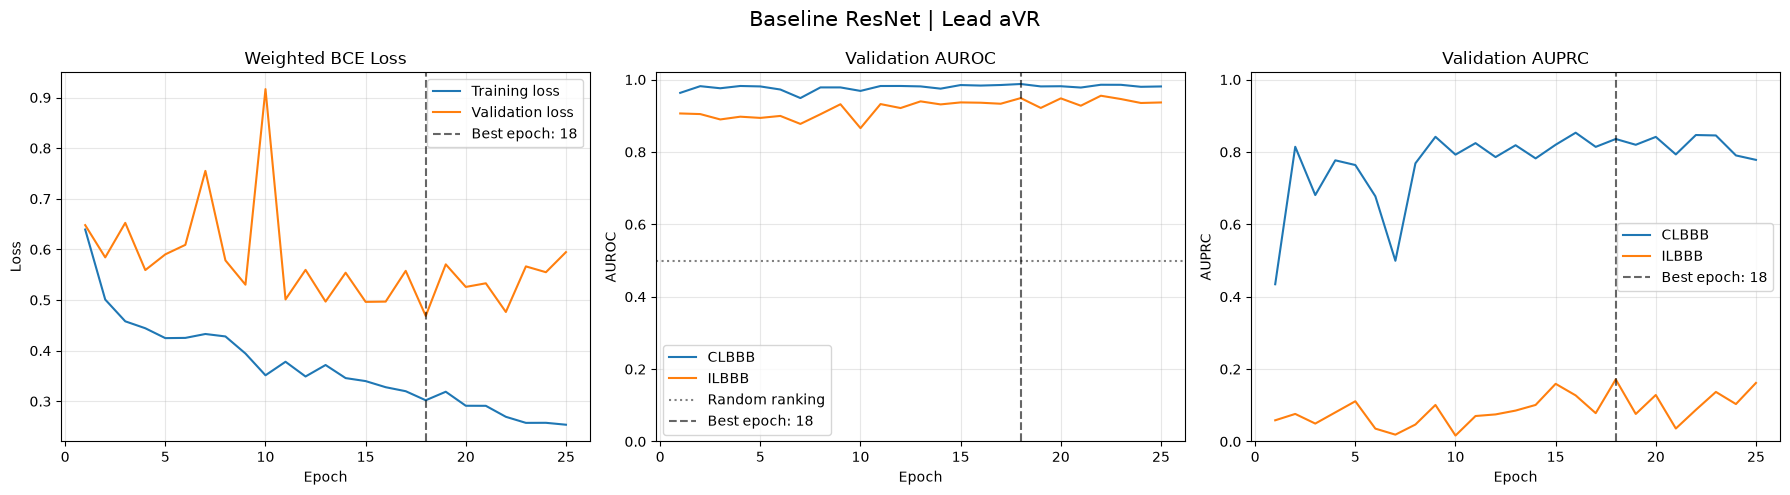

Architecture: baseline
Lead: aVF
Device: mps
Parameters: 242,114
Results: results/experiment3/full_ecg/baseline/aVF
Epoch 01/30 | Train: 0.9960 | Val: 1.1476 | Time: 21.3s
  CLBBB AUROC: 0.9037 | AUPRC: 0.1976
  ILBBB AUROC: 0.6765 | AUPRC: 0.0072
  Saved new best model
Epoch 02/30 | Train: 0.8472 | Val: 0.8747 | Time: 19.0s
  CLBBB AUROC: 0.9237 | AUPRC: 0.2975
  ILBBB AUROC: 0.8067 | AUPRC: 0.0118
  Saved new best model
Epoch 03/30 | Train: 0.7821 | Val: 0.9264 | Time: 19.5s
  CLBBB AUROC: 0.9245 | AUPRC: 0.3379
  ILBBB AUROC: 0.7837 | AUPRC: 0.0140
  No improvement: 1/7
Epoch 04/30 | Train: 0.7504 | Val: 0.8303 | Time: 18.8s
  CLBBB AUROC: 0.9282 | AUPRC: 0.3672
  ILBBB AUROC: 0.8357 | AUPRC: 0.0163
  Saved new best model
Epoch 05/30 | Train: 0.7022 | Val: 0.8142 | Time: 18.5s
  CLBBB AUROC: 0.9360 | AUPRC: 0.4313
  ILBBB AUROC: 0.8351 | AUPRC: 0.0172
  Saved new best model
Epoch 06/30 | Train: 0.7207 | Val: 0.8937 | Time: 18.5s
  CLBBB AUROC: 0.9362 | AUPRC: 0.3099
  ILBBB AUROC: 0

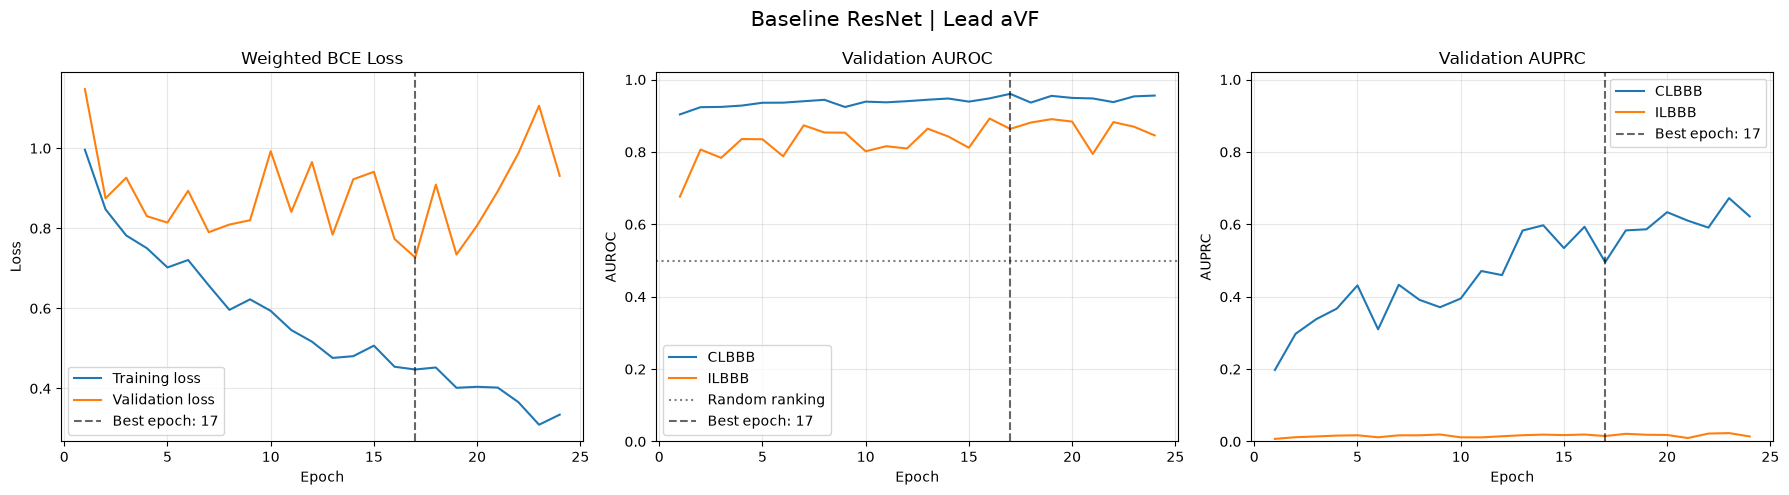

Architecture: improved
Lead: II
Device: mps
Parameters: 242,570
Results: results/experiment3/full_ecg/improved/II
Epoch 01/30 | Train: 0.9902 | Val: 1.2022 | Time: 20.6s
  CLBBB AUROC: 0.9489 | AUPRC: 0.3520
  ILBBB AUROC: 0.7515 | AUPRC: 0.0084
  Saved new best model
Epoch 02/30 | Train: 0.7289 | Val: 0.8593 | Time: 19.3s
  CLBBB AUROC: 0.9685 | AUPRC: 0.5727
  ILBBB AUROC: 0.8522 | AUPRC: 0.0438
  Saved new best model
Epoch 03/30 | Train: 0.6273 | Val: 0.9414 | Time: 19.3s
  CLBBB AUROC: 0.9714 | AUPRC: 0.5779
  ILBBB AUROC: 0.8292 | AUPRC: 0.0217
  No improvement: 1/7
Epoch 04/30 | Train: 0.5628 | Val: 0.8137 | Time: 19.8s
  CLBBB AUROC: 0.9685 | AUPRC: 0.6115
  ILBBB AUROC: 0.8413 | AUPRC: 0.0212
  Saved new best model
Epoch 05/30 | Train: 0.5327 | Val: 0.9159 | Time: 19.5s
  CLBBB AUROC: 0.9702 | AUPRC: 0.5245
  ILBBB AUROC: 0.8315 | AUPRC: 0.0190
  No improvement: 1/7
Epoch 06/30 | Train: 0.5060 | Val: 1.1517 | Time: 19.5s
  CLBBB AUROC: 0.9772 | AUPRC: 0.6171
  ILBBB AUROC: 0.81

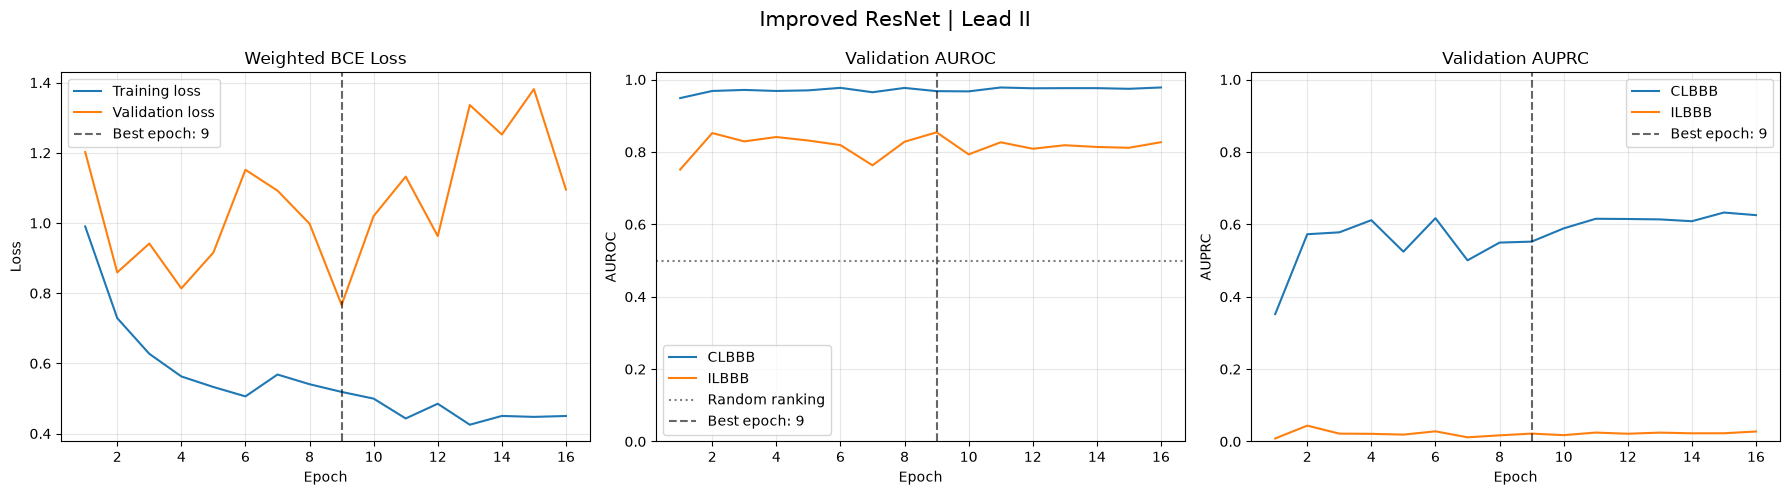

Architecture: improved
Lead: III
Device: mps
Parameters: 242,570
Results: results/experiment3/full_ecg/improved/III
Epoch 01/30 | Train: 1.4350 | Val: 1.5468 | Time: 19.6s
  CLBBB AUROC: 0.8797 | AUPRC: 0.2195
  ILBBB AUROC: 0.7019 | AUPRC: 0.0105
  Saved new best model
Epoch 02/30 | Train: 1.0780 | Val: 0.8721 | Time: 19.3s
  CLBBB AUROC: 0.9345 | AUPRC: 0.4856
  ILBBB AUROC: 0.8105 | AUPRC: 0.0303
  Saved new best model
Epoch 03/30 | Train: 0.8396 | Val: 1.0102 | Time: 19.9s
  CLBBB AUROC: 0.9473 | AUPRC: 0.4464
  ILBBB AUROC: 0.7997 | AUPRC: 0.0392
  No improvement: 1/7
Epoch 04/30 | Train: 0.8539 | Val: 0.7170 | Time: 19.6s
  CLBBB AUROC: 0.9526 | AUPRC: 0.4332
  ILBBB AUROC: 0.8721 | AUPRC: 0.0866
  Saved new best model
Epoch 05/30 | Train: 0.8120 | Val: 0.7592 | Time: 19.2s
  CLBBB AUROC: 0.9541 | AUPRC: 0.4634
  ILBBB AUROC: 0.8498 | AUPRC: 0.0538
  No improvement: 1/7
Epoch 06/30 | Train: 0.7603 | Val: 1.0205 | Time: 19.6s
  CLBBB AUROC: 0.9473 | AUPRC: 0.5525
  ILBBB AUROC: 0.

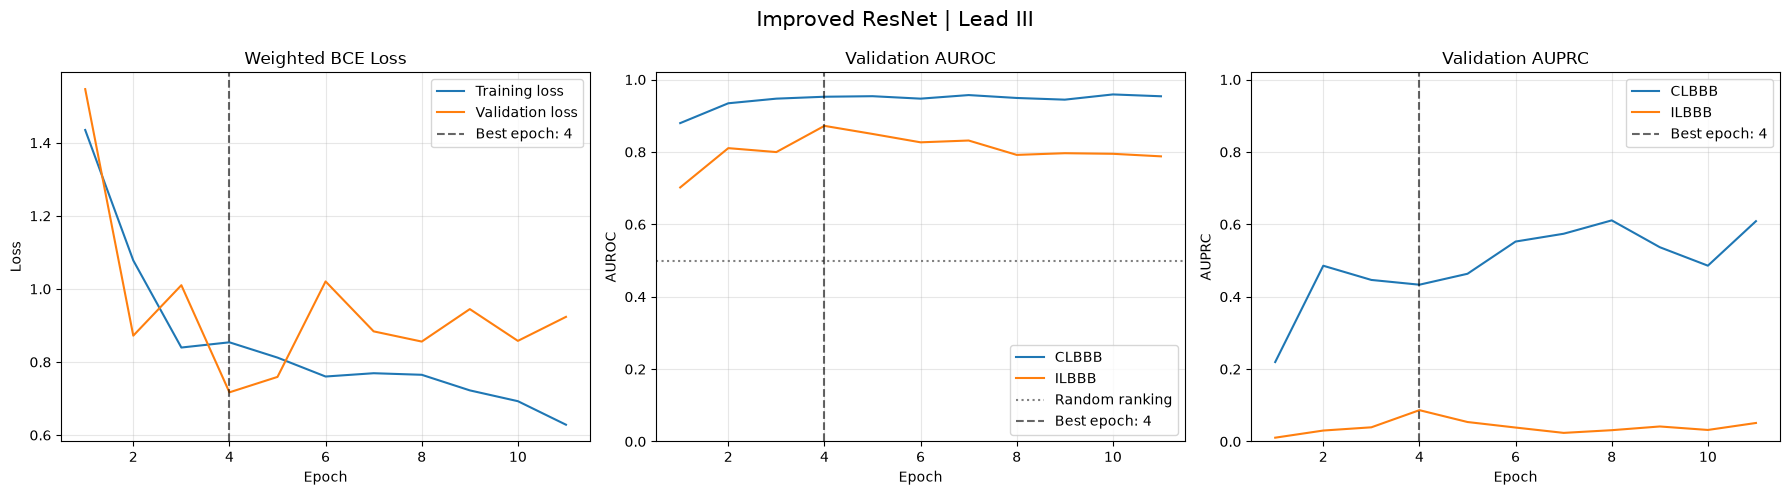

Architecture: improved
Lead: aVR
Device: mps
Parameters: 242,570
Results: results/experiment3/full_ecg/improved/aVR
Epoch 01/30 | Train: 1.1018 | Val: 1.2515 | Time: 19.7s
  CLBBB AUROC: 0.9699 | AUPRC: 0.4472
  ILBBB AUROC: 0.8485 | AUPRC: 0.0418
  Saved new best model
Epoch 02/30 | Train: 0.6871 | Val: 0.5777 | Time: 19.1s
  CLBBB AUROC: 0.9860 | AUPRC: 0.7170
  ILBBB AUROC: 0.9040 | AUPRC: 0.2094
  Saved new best model
Epoch 03/30 | Train: 0.5178 | Val: 0.6430 | Time: 19.3s
  CLBBB AUROC: 0.9877 | AUPRC: 0.7739
  ILBBB AUROC: 0.8896 | AUPRC: 0.0414
  No improvement: 1/7
Epoch 04/30 | Train: 0.5563 | Val: 0.5673 | Time: 16.7s
  CLBBB AUROC: 0.9699 | AUPRC: 0.6902
  ILBBB AUROC: 0.9301 | AUPRC: 0.2008
  Saved new best model
Epoch 05/30 | Train: 0.4838 | Val: 0.4998 | Time: 18.6s
  CLBBB AUROC: 0.9876 | AUPRC: 0.7290
  ILBBB AUROC: 0.9256 | AUPRC: 0.0780
  Saved new best model
Epoch 06/30 | Train: 0.4010 | Val: 0.6088 | Time: 19.1s
  CLBBB AUROC: 0.9873 | AUPRC: 0.8094
  ILBBB AUROC: 0

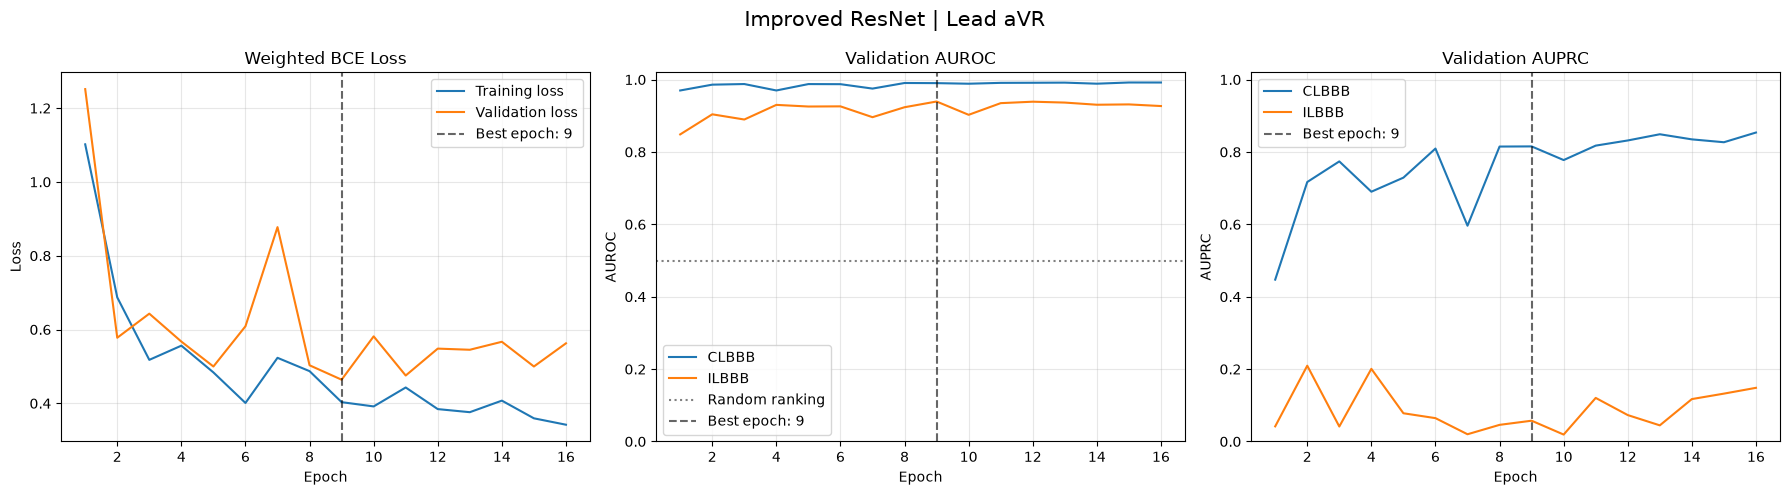

Architecture: improved
Lead: aVF
Device: mps
Parameters: 242,570
Results: results/experiment3/full_ecg/improved/aVF
Epoch 01/30 | Train: 1.2080 | Val: 1.4233 | Time: 19.8s
  CLBBB AUROC: 0.9191 | AUPRC: 0.2733
  ILBBB AUROC: 0.6231 | AUPRC: 0.0097
  Saved new best model
Epoch 02/30 | Train: 0.9051 | Val: 0.8434 | Time: 19.3s
  CLBBB AUROC: 0.9313 | AUPRC: 0.3587
  ILBBB AUROC: 0.8578 | AUPRC: 0.0238
  Saved new best model
Epoch 03/30 | Train: 0.8631 | Val: 1.0408 | Time: 19.3s
  CLBBB AUROC: 0.9312 | AUPRC: 0.4425
  ILBBB AUROC: 0.7841 | AUPRC: 0.0125
  No improvement: 1/7
Epoch 04/30 | Train: 0.8179 | Val: 0.7603 | Time: 19.3s
  CLBBB AUROC: 0.9356 | AUPRC: 0.5548
  ILBBB AUROC: 0.8697 | AUPRC: 0.0239
  Saved new best model
Epoch 05/30 | Train: 0.7411 | Val: 0.7614 | Time: 19.3s
  CLBBB AUROC: 0.9371 | AUPRC: 0.4445
  ILBBB AUROC: 0.8771 | AUPRC: 0.0225
  No improvement: 1/7
Epoch 06/30 | Train: 0.6912 | Val: 0.8626 | Time: 19.3s
  CLBBB AUROC: 0.9473 | AUPRC: 0.4861
  ILBBB AUROC: 0.

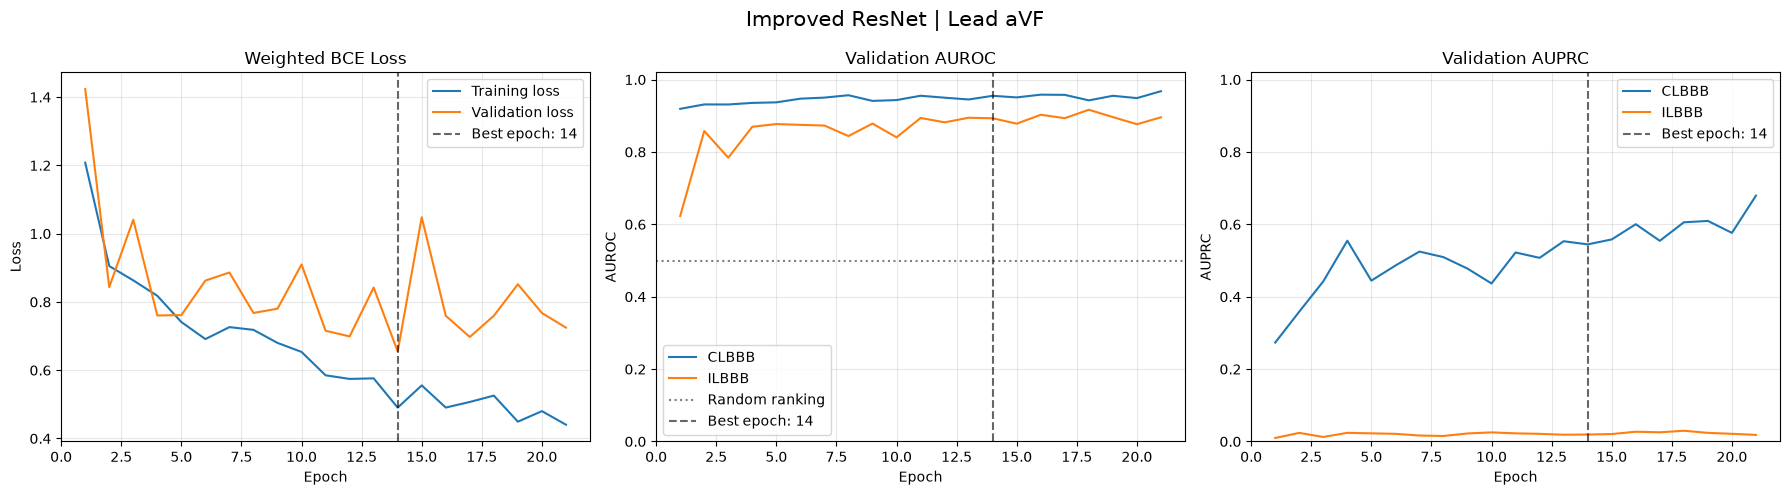


All full-ECG training runs completed.
Elapsed time for this session: 41.15 minutes


In [45]:
all_training_summaries = []

total_start_time = time.perf_counter()

for config in training_configs:

    architecture = config["architecture"]

    lead = config["lead"]

    run_dir = get_run_directory(
        architecture,
        lead
    )

    # -----------------------------------
    # Skip previously completed models
    # -----------------------------------

    if is_training_complete(architecture, lead):

        print(
            f"Skipping completed model: "
            f"{architecture} | Lead {lead}"
        )

        history_df = pd.read_csv(
            run_dir / "training_history.csv"
        )

        summary_df = pd.read_csv(
            run_dir / "validation_metrics.csv"
        )

    # -----------------------------------
    # Train pending models
    # -----------------------------------

    else:

        history_df, summary_df = train_model(

            architecture=architecture,

            lead=lead,

            max_epochs=MAX_EPOCHS,

            patience=PATIENCE,

            learning_rate=LEARNING_RATE,

            batch_size=BATCH_SIZE,

            seed=SEED

        )

    # -----------------------------------
    # Save training curves
    # -----------------------------------

    if not (run_dir / "training_curves.png").exists():

        best_epoch = int(
            summary_df.iloc[0]["best_epoch"]
        )

        plot_training_history(

            history=history_df,

            architecture=architecture,

            lead=lead,

            best_epoch=best_epoch

        )

    # -----------------------------------
    # Collect validation summaries
    # -----------------------------------

    all_training_summaries.append(summary_df)


total_elapsed_time = (
    time.perf_counter() - total_start_time
)

print("\n" + "=" * 70)

print("All full-ECG training runs completed.")

print(
    f"Elapsed time for this session: "
    f"{total_elapsed_time / 60:.2f} minutes"
)

print("=" * 70)

In [46]:
full_ecg_validation_results = pd.concat(

    all_training_summaries,

    ignore_index=True

)

assert len(full_ecg_validation_results) == 8

assert not full_ecg_validation_results.duplicated(

    subset=["architecture", "lead"]

).any()


full_ecg_validation_results.to_csv(

    RESULTS_DIR
    / "full_ecg"
    / "all_validation_results.csv",

    index=False

)

display(
    full_ecg_validation_results.round(4)
)

,architecture,lead,representation,best_epoch,epochs_trained,best_val_loss,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC,training_time_seconds
0,baseline,II,full_ecg,9,16,0.6737,0.9708,0.6055,0.8754,0.0280,278.8476
1,baseline,III,full_ecg,12,19,0.6548,0.9613,0.5843,0.8907,0.0267,319.6565
2,baseline,aVR,full_ecg,18,25,0.4686,0.9878,0.8358,0.9489,0.1716,450.1231
3,baseline,aVF,full_ecg,17,24,0.7272,0.9606,0.4955,0.8636,0.0151,452.5663
4,improved,II,full_ecg,9,16,0.7667,0.9681,0.5523,0.8543,0.0218,312.2346
5,improved,III,full_ecg,4,11,0.7170,0.9526,0.4332,0.8721,0.0866,214.5606
6,improved,aVR,full_ecg,9,16,0.4641,0.9902,0.8154,0.9394,0.0574,305.6866
7,improved,aVF,full_ecg,14,21,0.6550,0.9551,0.5446,0.8931,0.0193,411.4923


In [47]:
metric_columns = [

    "lead",

    "architecture",

    "best_epoch",

    "CLBBB_AUROC",

    "CLBBB_AUPRC",

    "ILBBB_AUROC",

    "ILBBB_AUPRC"

]


display(

    full_ecg_validation_results[
        metric_columns
    ].round(4)

)

,lead,architecture,best_epoch,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC
0,II,baseline,9,0.9708,0.6055,0.8754,0.0280
1,III,baseline,12,0.9613,0.5843,0.8907,0.0267
2,aVR,baseline,18,0.9878,0.8358,0.9489,0.1716
3,aVF,baseline,17,0.9606,0.4955,0.8636,0.0151
4,II,improved,9,0.9681,0.5523,0.8543,0.0218
5,III,improved,4,0.9526,0.4332,0.8721,0.0866
6,aVR,improved,9,0.9902,0.8154,0.9394,0.0574
7,aVF,improved,14,0.9551,0.5446,0.8931,0.0193


## 8. Validation Results and Model Selection

Compare eight independently trained single-lead models
using the full 10-second ECG representation.

Research questions:
1. Which non-diagnostic lead has the strongest
   predictive performance?
2. Does the proposed improved ResNet outperform
   the baseline ResNet?
3. Are the results consistent across CLBBB and ILBBB?

Evaluation metrics:
- CLBBB AUROC
- CLBBB AUPRC (average precision)
- ILBBB AUROC
- ILBBB AUPRC (average precision)

Model selection uses validation results only.
The test dataset remains held out.

In [48]:
FULL_ECG_RESULTS_DIR = RESULTS_DIR / "full_ecg"

validation_results = pd.read_csv(
    FULL_ECG_RESULTS_DIR / "all_validation_results.csv"
)

METRICS = [
    "CLBBB_AUROC",
    "CLBBB_AUPRC",
    "ILBBB_AUROC",
    "ILBBB_AUPRC"
]

assert len(validation_results) == 8

assert not validation_results.duplicated(
    subset=["architecture", "lead"]
).any()

display(
    validation_results[
        ["lead", "architecture"] + METRICS
    ].round(4)
)

,lead,architecture,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC
0,II,baseline,0.9708,0.6055,0.8754,0.0280
1,III,baseline,0.9613,0.5843,0.8907,0.0267
2,aVR,baseline,0.9878,0.8358,0.9489,0.1716
3,aVF,baseline,0.9606,0.4955,0.8636,0.0151
4,II,improved,0.9681,0.5523,0.8543,0.0218
5,III,improved,0.9526,0.4332,0.8721,0.0866
6,aVR,improved,0.9902,0.8154,0.9394,0.0574
7,aVF,improved,0.9551,0.5446,0.8931,0.0193


In [49]:
architecture_comparison = (
    validation_results
    .groupby("architecture")[METRICS]
    .mean()
)

display(architecture_comparison.round(4))

architecture_comparison.to_csv(
    FULL_ECG_RESULTS_DIR
    / "architecture_comparison.csv"
)

,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC
architecture,,,,
baseline,0.9701,0.6303,0.8946,0.0603
improved,0.9665,0.5864,0.8897,0.0463


In [50]:
baseline_results = (
    validation_results[
        validation_results["architecture"] == "baseline"
    ]
    .set_index("lead")[METRICS]
    .reindex(TARGET_LEADS)
)

improved_results = (
    validation_results[
        validation_results["architecture"] == "improved"
    ]
    .set_index("lead")[METRICS]
    .reindex(TARGET_LEADS)
)

architecture_differences = (
    improved_results - baseline_results
)

display(
    architecture_differences.round(4)
)

architecture_differences.to_csv(
    FULL_ECG_RESULTS_DIR
    / "architecture_differences.csv"
)

print(
    "Metrics favoring baseline:",
    (architecture_differences < 0).sum().sum()
)

print(
    "Metrics favoring improved:",
    (architecture_differences > 0).sum().sum()
)

,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC
lead,,,,
II,-0.0028,-0.0533,-0.0211,-0.0062
III,-0.0087,-0.1511,-0.0186,0.0599
aVR,0.0024,-0.0205,-0.0095,-0.1141
aVF,-0.0055,0.0492,0.0295,0.0042


Metrics favoring baseline: 11
Metrics favoring improved: 5


In [51]:
def plot_architecture_comparison(
    results,
    representation,
    save_dir
):

    fig, axes = plt.subplots(
        2, 2,
        figsize=(14, 10)
    )

    x = np.arange(len(TARGET_LEADS))

    width = 0.35

    for ax, metric in zip(axes.ravel(), METRICS):

        baseline_values = (
            results[
                results["architecture"] == "baseline"
            ]
            .set_index("lead")
            .reindex(TARGET_LEADS)[metric]
        )

        improved_values = (
            results[
                results["architecture"] == "improved"
            ]
            .set_index("lead")
            .reindex(TARGET_LEADS)[metric]
        )

        bars_baseline = ax.bar(
            x - width / 2,
            baseline_values,
            width,
            label="Baseline"
        )

        bars_improved = ax.bar(
            x + width / 2,
            improved_values,
            width,
            label="Improved"
        )

        ax.bar_label(
            bars_baseline,
            fmt="%.3f",
            padding=3,
            fontsize=9
        )

        ax.bar_label(
            bars_improved,
            fmt="%.3f",
            padding=3,
            fontsize=9
        )

        ax.set_xticks(x)
        ax.set_xticklabels(TARGET_LEADS)

        ax.set_title(metric.replace("_", " "))
        ax.set_xlabel("ECG Lead")
        ax.set_ylabel(metric.split("_")[-1])

        if "AUROC" in metric:

            ax.axhline(
                0.5,
                linestyle="--",
                color="gray",
                label="Random ranking"
            )

            ax.set_ylim(0, 1.1)

        else:

            max_value = max(
                baseline_values.max(),
                improved_values.max()
            )

            ax.set_ylim(0, max_value * 1.2)

        ax.legend()
        ax.grid(axis="y", alpha=0.3)

    fig.suptitle(
        f"Validation Performance — {representation}",
        fontsize=16
    )

    plt.tight_layout()

    fig.savefig(
        save_dir / "validation_comparison.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

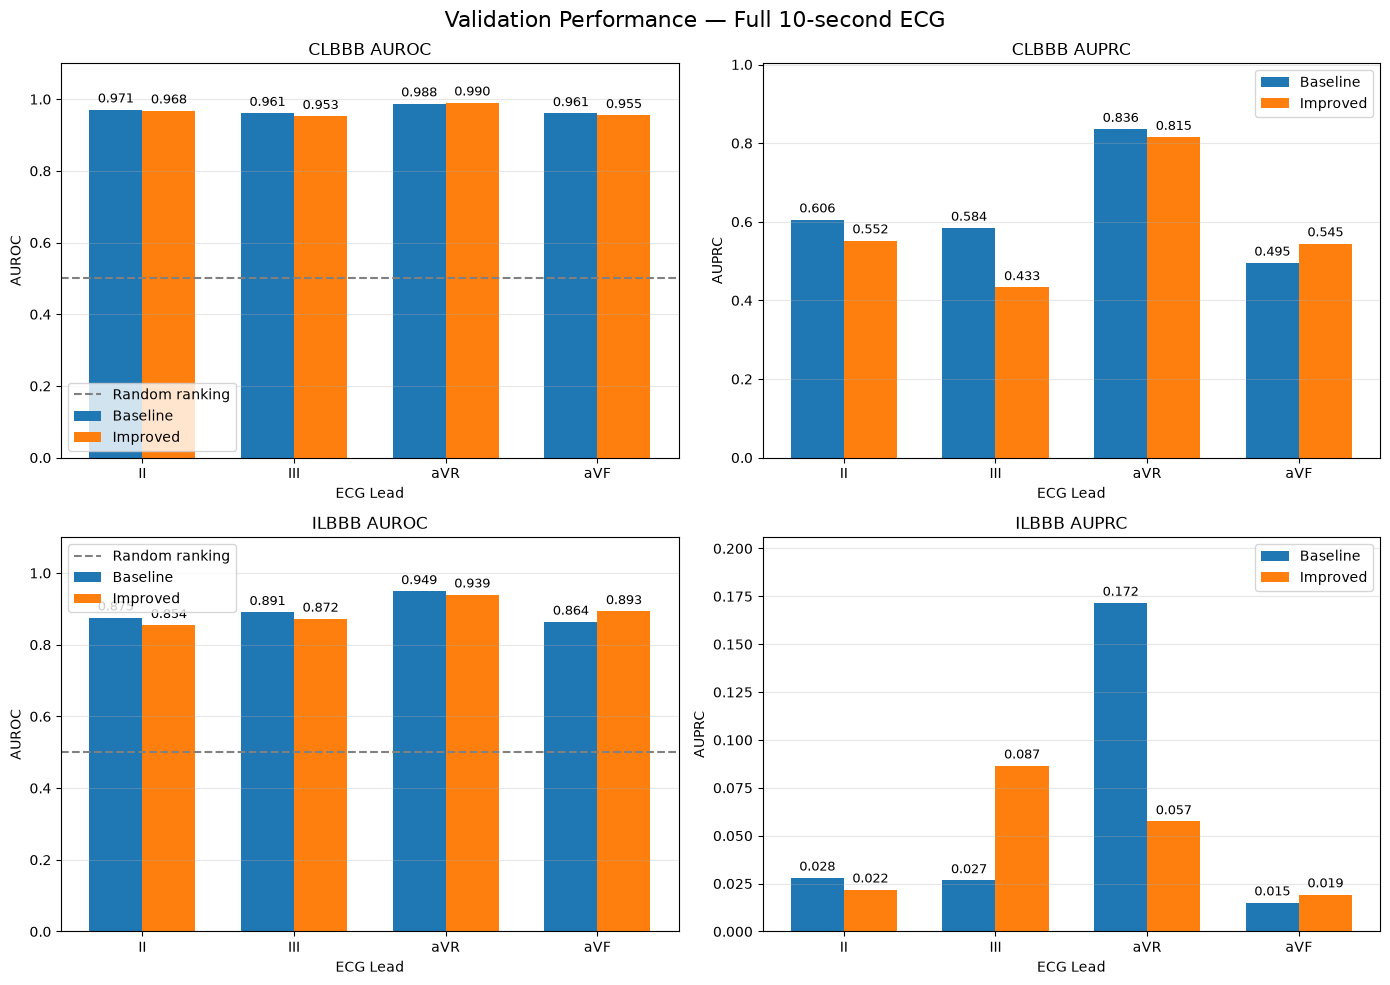

In [52]:
plot_architecture_comparison(
    results=validation_results,
    representation="Full 10-second ECG",
    save_dir=FULL_ECG_RESULTS_DIR
)

In [53]:
model_ranking = validation_results.sort_values(
    by=["CLBBB_AUPRC", "CLBBB_AUROC"],
    ascending=False
).reset_index(drop=True)

model_ranking.insert(
    0,
    "rank",
    np.arange(1, len(model_ranking) + 1)
)

display(
    model_ranking[
        ["rank", "lead", "architecture"] + METRICS
    ].round(4)
)

model_ranking.to_csv(
    FULL_ECG_RESULTS_DIR
    / "validation_model_ranking.csv",
    index=False
)

,rank,lead,architecture,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC
0,1,aVR,baseline,0.9878,0.8358,0.9489,0.1716
1,2,aVR,improved,0.9902,0.8154,0.9394,0.0574
2,3,II,baseline,0.9708,0.6055,0.8754,0.0280
3,4,III,baseline,0.9613,0.5843,0.8907,0.0267
4,5,II,improved,0.9681,0.5523,0.8543,0.0218
5,6,aVF,improved,0.9551,0.5446,0.8931,0.0193
6,7,aVF,baseline,0.9606,0.4955,0.8636,0.0151
7,8,III,improved,0.9526,0.4332,0.8721,0.0866


In [54]:
selected_model = model_ranking.iloc[0]

selection_summary = {
    "representation": "full_ecg",
    "preferred_architecture": "baseline",

    "selected_lead": selected_model["lead"],

    "selected_architecture": (
        selected_model["architecture"]
    ),

    "selection_metric": "CLBBB_AUPRC",

    "selection_metric_value": float(
        selected_model["CLBBB_AUPRC"]
    ),

    "selection_split": "validation",

    "selection_criterion_timing": (
        "Chosen after initial validation comparison"
    ),

    "test_evaluation": (
        "Evaluate all eight trained models"
    ),

    "ablation_study": False
}

with open(
    FULL_ECG_RESULTS_DIR / "model_selection.json",
    "w"
) as f:

    json.dump(
        selection_summary,
        f,
        indent=4
    )

print(json.dumps(selection_summary, indent=4))

{
    "representation": "full_ecg",
    "preferred_architecture": "baseline",
    "selected_lead": "aVR",
    "selected_architecture": "baseline",
    "selection_metric": "CLBBB_AUPRC",
    "selection_metric_value": 0.8358172020730906,
    "selection_split": "validation",
    "selection_criterion_timing": "Chosen after initial validation comparison",
    "test_evaluation": "Evaluate all eight trained models",
    "ablation_study": false
}


## 9. Held-Out Test Evaluation

Evaluate all eight independently trained models
on the Dataset 2 test partition.

- Test dataset: PTB-XL fold 10
- ECG representation: Full 10-second ECG
- Test recordings: 2,198
- CLBBB-positive recordings: 54
- ILBBB-positive recordings: 8

Load the best checkpoints selected using validation
loss. Do not perform additional model optimization.

Report:
- Per-label AUROC
- Per-label AUPRC (average precision)
- ROC curves
- Precision-recall curves
- Architecture and lead comparisons
- Validation-to-test performance differences

In [55]:
def load_trained_model(
    architecture,
    lead,
    representation="full_ecg"
):

    run_dir = get_run_directory(
        architecture,
        lead,
        representation=representation
    )

    checkpoint_path = run_dir / "best_model.pt"

    if not checkpoint_path.exists():

        raise FileNotFoundError(
            f"Missing checkpoint: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    # Verify checkpoint identity
    assert checkpoint["architecture"] == architecture

    assert checkpoint["lead"] == lead

    # Reconstruct model architecture
    model = build_model(architecture)

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model = model.to(device)

    model.eval()

    return model, checkpoint

In [56]:
def evaluate_test_model(architecture, lead):

    run_dir = get_run_directory(
        architecture,
        lead,
        representation="full_ecg"
    )

    # Load best validation checkpoint
    model, checkpoint = load_trained_model(
        architecture,
        lead
    )

    # Obtain test DataLoader
    _, _, test_loader = create_dataloaders(
        lead,
        batch_size=BATCH_SIZE
    )

    # Use original training-set positive weights
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=checkpoint["pos_weight"].to(device)
    )

    # Evaluate test dataset
    test_loss, test_metrics, targets, scores = (
        evaluate_model(
            model,
            test_loader,
            criterion,
            device
        )
    )

    # Verify prediction dimensions and label ordering
    assert targets.shape == y_test.shape
    assert scores.shape == y_test.shape

    np.testing.assert_array_equal(
        targets,
        np.asarray(y_test)
    )

    assert np.isfinite(scores).all()

    # Construct result summary
    summary = {
        "architecture": architecture,
        "lead": lead,
        "representation": "full_ecg",
        "best_epoch": checkpoint["epoch"],
        "test_loss": test_loss,
        **test_metrics
    }

    summary_df = pd.DataFrame([summary])

    # Save test results
    summary_df.to_csv(
        run_dir / "test_metrics.csv",
        index=False
    )

    np.save(
        run_dir / "test_scores.npy",
        scores
    )

    np.save(
        run_dir / "test_targets.npy",
        targets
    )

    print(f"{architecture} | Lead {lead}")
    print(f"  Test loss: {test_loss:.4f}")

    for metric, value in test_metrics.items():

        print(f"  {metric}: {value:.4f}")

    print()

    # Release GPU memory
    del model, checkpoint, criterion

    if device.type == "mps":

        torch.mps.empty_cache()

    elif device.type == "cuda":

        torch.cuda.empty_cache()

    return summary_df

In [57]:
all_test_summaries = []

start_time = time.perf_counter()

for architecture in ARCHITECTURES:

    for lead in TARGET_LEADS:

        summary_df = evaluate_test_model(
            architecture,
            lead
        )

        all_test_summaries.append(
            summary_df
        )

full_ecg_test_results = pd.concat(
    all_test_summaries,
    ignore_index=True
)

assert len(full_ecg_test_results) == 8

assert not full_ecg_test_results.duplicated(
    subset=["architecture", "lead"]
).any()

full_ecg_test_results.to_csv(
    FULL_ECG_RESULTS_DIR
    / "all_test_results.csv",
    index=False
)

elapsed_time = time.perf_counter() - start_time

print("=" * 60)
print("All eight test evaluations completed.")
print(f"Total evaluation time: {elapsed_time:.2f} seconds")
print("=" * 60)

display(full_ecg_test_results.round(4))

baseline | Lead II
  Test loss: 0.7205
  CLBBB_AUROC: 0.9817
  CLBBB_AUPRC: 0.6043
  ILBBB_AUROC: 0.8725
  ILBBB_AUPRC: 0.0575

baseline | Lead III
  Test loss: 0.4476
  CLBBB_AUROC: 0.9855
  CLBBB_AUPRC: 0.6778
  ILBBB_AUROC: 0.9584
  ILBBB_AUPRC: 0.0947

baseline | Lead aVR
  Test loss: 0.4369
  CLBBB_AUROC: 0.9961
  CLBBB_AUPRC: 0.8730
  ILBBB_AUROC: 0.9322
  ILBBB_AUPRC: 0.1222

baseline | Lead aVF
  Test loss: 0.5179
  CLBBB_AUROC: 0.9763
  CLBBB_AUPRC: 0.5216
  ILBBB_AUROC: 0.9335
  ILBBB_AUPRC: 0.0416

improved | Lead II
  Test loss: 0.8369
  CLBBB_AUROC: 0.9784
  CLBBB_AUPRC: 0.6743
  ILBBB_AUROC: 0.8513
  ILBBB_AUPRC: 0.0507

improved | Lead III
  Test loss: 0.8546
  CLBBB_AUROC: 0.9618
  CLBBB_AUPRC: 0.4539
  ILBBB_AUROC: 0.8012
  ILBBB_AUPRC: 0.0179

improved | Lead aVR
  Test loss: 0.5876
  CLBBB_AUROC: 0.9945
  CLBBB_AUPRC: 0.8541
  ILBBB_AUROC: 0.8918
  ILBBB_AUPRC: 0.1030

improved | Lead aVF
  Test loss: 0.9220
  CLBBB_AUROC: 0.9706
  CLBBB_AUPRC: 0.6273
  ILBBB_AUROC: 

,architecture,lead,representation,best_epoch,test_loss,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC
0,baseline,II,full_ecg,9,0.7205,0.9817,0.6043,0.8725,0.0575
1,baseline,III,full_ecg,12,0.4476,0.9855,0.6778,0.9584,0.0947
2,baseline,aVR,full_ecg,18,0.4369,0.9961,0.8730,0.9322,0.1222
3,baseline,aVF,full_ecg,17,0.5179,0.9763,0.5216,0.9335,0.0416
4,improved,II,full_ecg,9,0.8369,0.9784,0.6743,0.8513,0.0507
5,improved,III,full_ecg,4,0.8546,0.9618,0.4539,0.8012,0.0179
6,improved,aVR,full_ecg,9,0.5876,0.9945,0.8541,0.8918,0.1030
7,improved,aVF,full_ecg,14,0.9220,0.9706,0.6273,0.8204,0.1027


In [58]:
display(
    full_ecg_test_results[
        ["lead", "architecture"] + METRICS
    ].round(4)
)

,lead,architecture,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC
0,II,baseline,0.9817,0.6043,0.8725,0.0575
1,III,baseline,0.9855,0.6778,0.9584,0.0947
2,aVR,baseline,0.9961,0.8730,0.9322,0.1222
3,aVF,baseline,0.9763,0.5216,0.9335,0.0416
4,II,improved,0.9784,0.6743,0.8513,0.0507
5,III,improved,0.9618,0.4539,0.8012,0.0179
6,aVR,improved,0.9945,0.8541,0.8918,0.1030
7,aVF,improved,0.9706,0.6273,0.8204,0.1027


In [59]:
test_architecture_comparison = (
    full_ecg_test_results
    .groupby("architecture")[METRICS]
    .mean()
)

display(
    test_architecture_comparison.round(4)
)

test_architecture_comparison.to_csv(
    FULL_ECG_RESULTS_DIR
    / "test_architecture_comparison.csv"
)

,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC
architecture,,,,
baseline,0.9849,0.6692,0.9242,0.0790
improved,0.9763,0.6524,0.8412,0.0686


In [60]:
test_baseline_results = (
    full_ecg_test_results[
        full_ecg_test_results["architecture"]
        == "baseline"
    ]
    .set_index("lead")[METRICS]
    .reindex(TARGET_LEADS)
)

test_improved_results = (
    full_ecg_test_results[
        full_ecg_test_results["architecture"]
        == "improved"
    ]
    .set_index("lead")[METRICS]
    .reindex(TARGET_LEADS)
)

test_architecture_differences = (
    test_improved_results - test_baseline_results
)

display(
    test_architecture_differences.round(4)
)

test_architecture_differences.to_csv(
    FULL_ECG_RESULTS_DIR
    / "test_architecture_differences.csv"
)

print(
    "Metrics favoring baseline:",
    (test_architecture_differences < 0).sum().sum()
)

print(
    "Metrics favoring improved:",
    (test_architecture_differences > 0).sum().sum()
)

,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC
lead,,,,
II,-0.0033,0.0699,-0.0213,-0.0068
III,-0.0237,-0.2238,-0.1572,-0.0768
aVR,-0.0015,-0.0189,-0.0404,-0.0192
aVF,-0.0057,0.1057,-0.1131,0.0611


Metrics favoring baseline: 13
Metrics favoring improved: 3


In [61]:
def plot_evaluation_curves(
    architecture,
    label,
    curve_type="ROC",
    split="test",
    representation="full_ecg"
):

    label_idx = LABELS.index(label)

    fig, ax = plt.subplots(
        figsize=(8, 6)
    )

    prevalence = None

    for lead in TARGET_LEADS:

        run_dir = get_run_directory(
            architecture,
            lead,
            representation=representation
        )

        targets = np.load(
            run_dir / f"{split}_targets.npy"
        )[:, label_idx]

        scores = np.load(
            run_dir / f"{split}_scores.npy"
        )[:, label_idx]

        prevalence = targets.mean()

        if curve_type == "ROC":

            fpr, tpr, _ = roc_curve(
                targets,
                scores
            )

            metric = roc_auc_score(
                targets,
                scores
            )

            ax.plot(
                fpr,
                tpr,
                linewidth=2,
                label=f"{lead}: AUROC = {metric:.4f}"
            )

        elif curve_type == "PR":

            precision, recall, _ = (
                precision_recall_curve(
                    targets,
                    scores
                )
            )

            metric = average_precision_score(
                targets,
                scores
            )

            ax.step(
                recall[::-1],
                precision[::-1],
                where="post",
                linewidth=2,
                label=f"{lead}: AP = {metric:.4f}"
            )

        else:

            raise ValueError(
                "curve_type must be ROC or PR"
            )

    if curve_type == "ROC":

        ax.plot(
            [0, 1],
            [0, 1],
            linestyle="--",
            color="gray",
            label="Random ranking"
        )

        ax.set_xlabel("False Positive Rate")
        ax.set_ylabel("True Positive Rate")

    else:

        ax.axhline(
            prevalence,
            linestyle="--",
            color="gray",
            label=f"Prevalence = {prevalence:.4f}"
        )

        ax.set_xlabel("Recall")
        ax.set_ylabel("Precision")

    ax.set_title(
        f"{split.capitalize()} {curve_type} Curve\n"
        f"{architecture.capitalize()} ResNet | {label}"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()

    save_dir = RESULTS_DIR / representation / "curves"

    save_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    fig.savefig(
        save_dir
        / f"{split}_{architecture}_{label}_{curve_type}.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

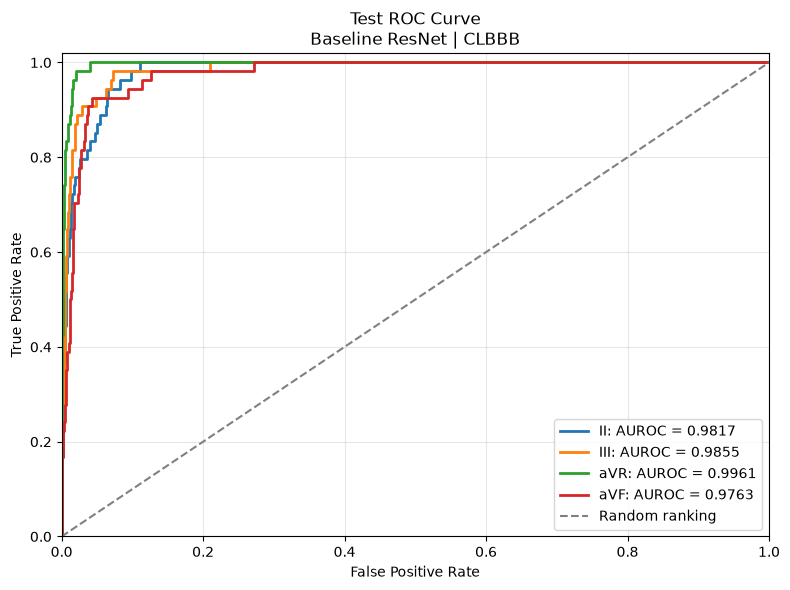

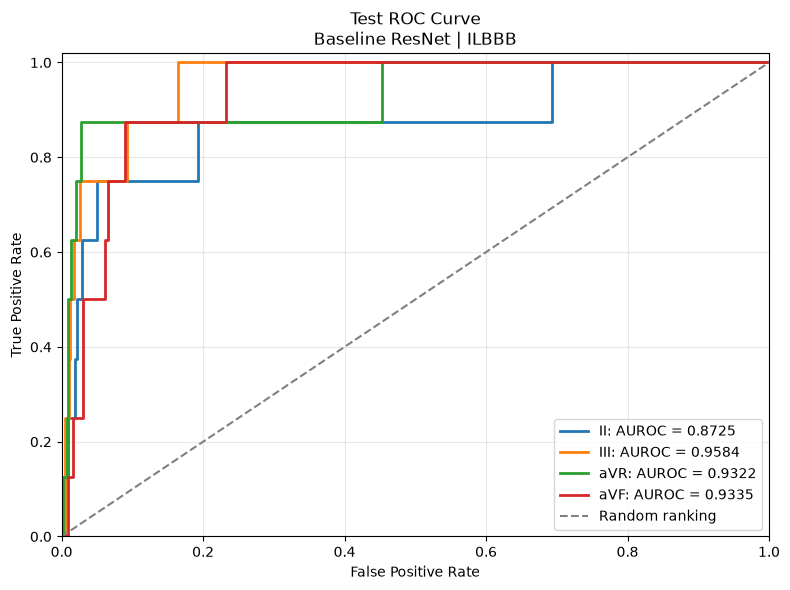

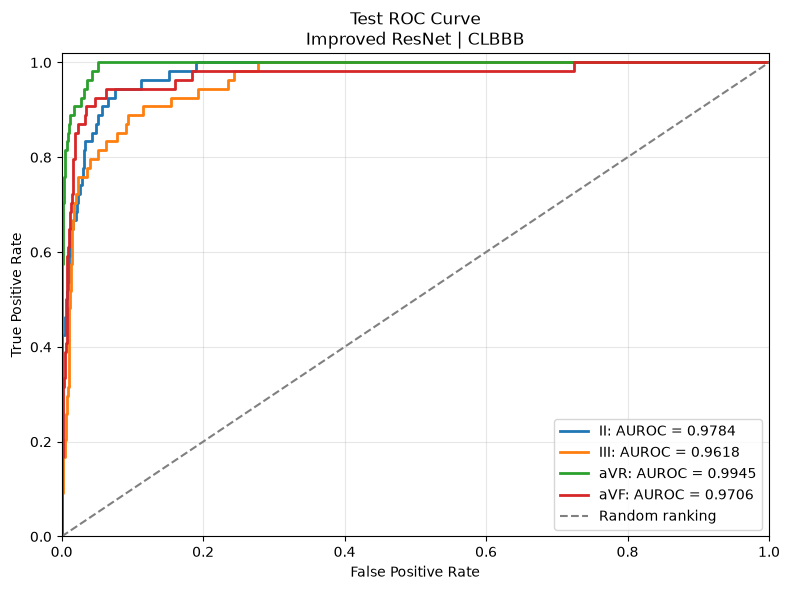

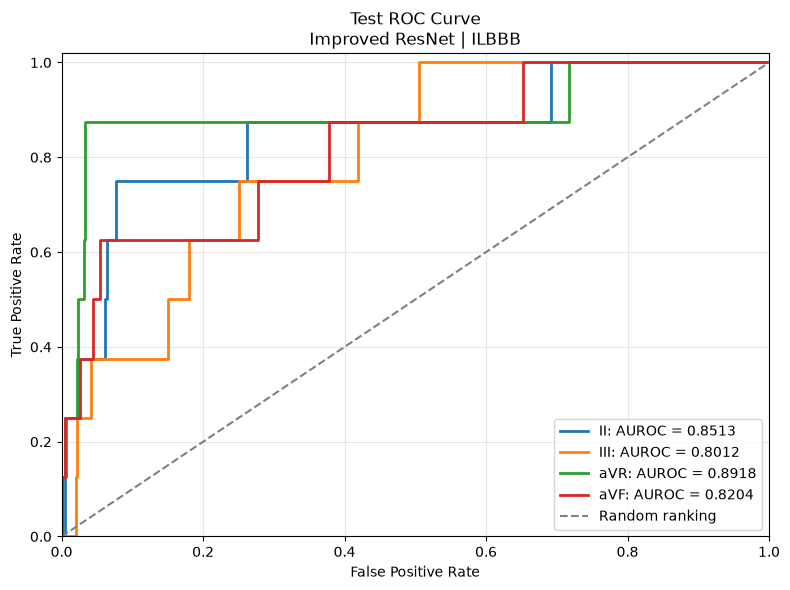

In [62]:
for architecture in ARCHITECTURES:

    for label in LABELS:

        plot_evaluation_curves(
            architecture=architecture,
            label=label,
            curve_type="ROC",
            split="test"
        )

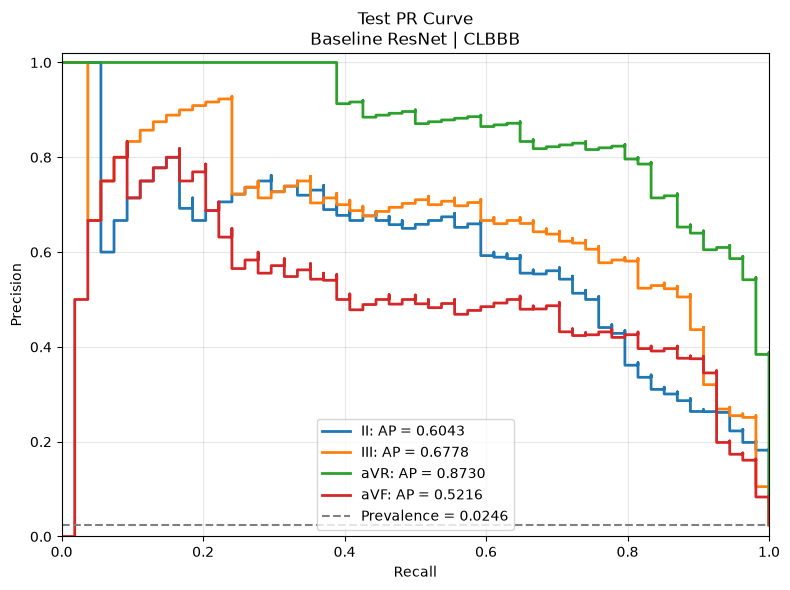

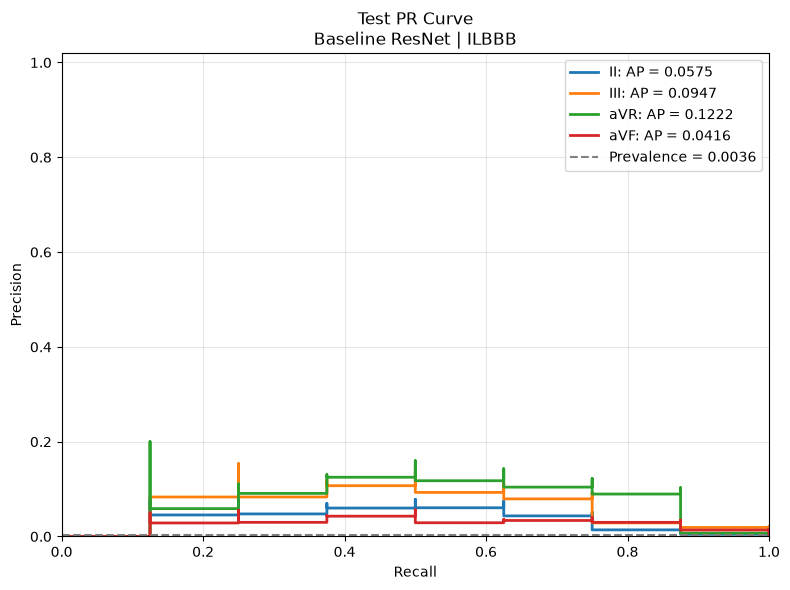

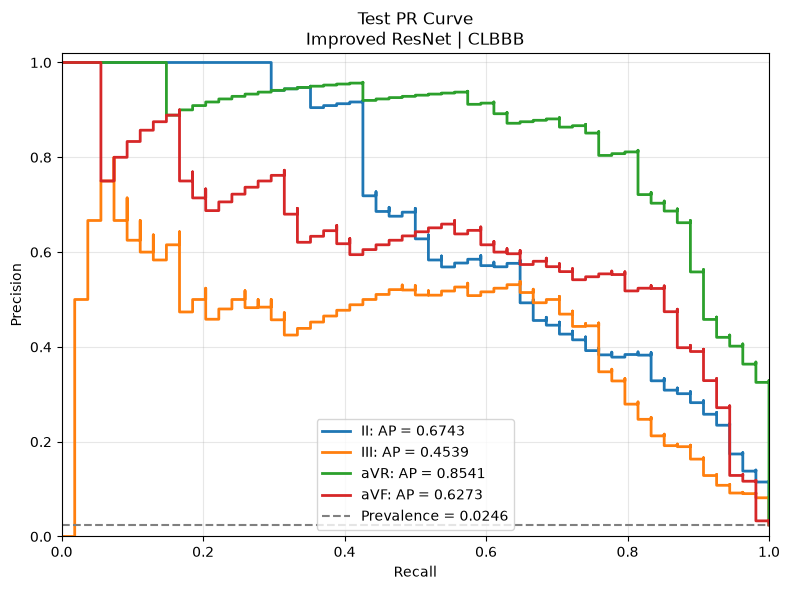

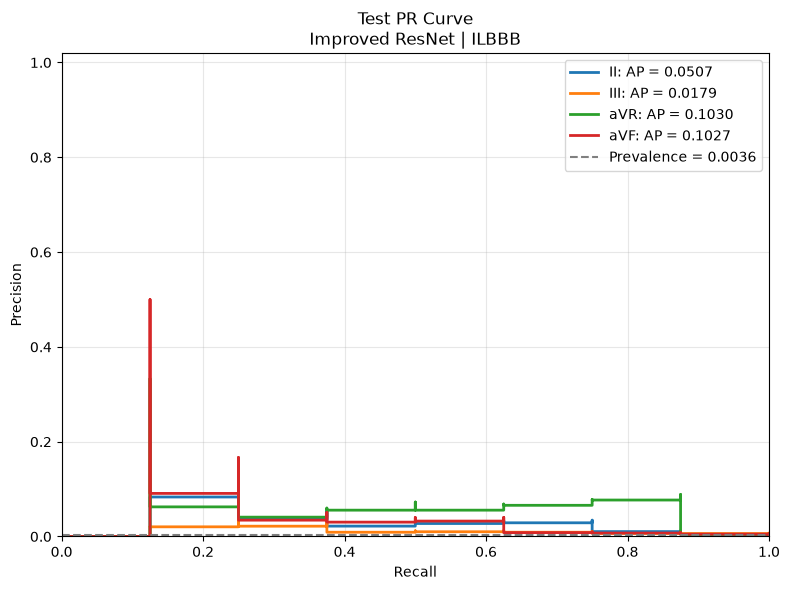

In [63]:
for architecture in ARCHITECTURES:

    for label in LABELS:

        plot_evaluation_curves(
            architecture=architecture,
            label=label,
            curve_type="PR",
            split="test"
        )

In [64]:
comparison_results = validation_results[
    ["architecture", "lead"] + METRICS
].merge(
    full_ecg_test_results[
        ["architecture", "lead"] + METRICS
    ],
    on=["architecture", "lead"],
    suffixes=("_val", "_test"),
    validate="one_to_one"
)

for metric in METRICS:

    comparison_results[f"{metric}_difference"] = (
        comparison_results[f"{metric}_test"]
        - comparison_results[f"{metric}_val"]
    )

difference_columns = [
    f"{metric}_difference"
    for metric in METRICS
]

display(
    comparison_results[
        ["architecture", "lead"]
        + difference_columns
    ].round(4)
)

comparison_results.to_csv(
    FULL_ECG_RESULTS_DIR
    / "validation_test_comparison.csv",
    index=False
)

,architecture,lead,CLBBB_AUROC_difference,CLBBB_AUPRC_difference,ILBBB_AUROC_difference,ILBBB_AUPRC_difference
0,baseline,II,0.0108,-0.0012,-0.0028,0.0294
1,baseline,III,0.0242,0.0934,0.0677,0.0680
2,baseline,aVR,0.0083,0.0372,-0.0167,-0.0493
3,baseline,aVF,0.0158,0.0261,0.0699,0.0265
4,improved,II,0.0103,0.1220,-0.0030,0.0289
5,improved,III,0.0092,0.0207,-0.0709,-0.0686
6,improved,aVR,0.0043,0.0387,-0.0476,0.0455
7,improved,aVF,0.0155,0.0827,-0.0727,0.0834


In [65]:
selected_model_comparison = comparison_results[
    (comparison_results["architecture"] == "baseline")
    &
    (comparison_results["lead"] == "aVR")
]

selected_model_summary = []

for metric in METRICS:

    row = selected_model_comparison.iloc[0]

    selected_model_summary.append({

        "Metric": metric,

        "Validation": row[f"{metric}_val"],

        "Test": row[f"{metric}_test"],

        "Difference": row[f"{metric}_difference"]

    })

selected_model_summary = pd.DataFrame(
    selected_model_summary
)

display(
    selected_model_summary.round(4)
)

selected_model_summary.to_csv(
    FULL_ECG_RESULTS_DIR
    / "selected_model_comparison.csv",
    index=False
)

,Metric,Validation,Test,Difference
0,CLBBB_AUROC,0.9878,0.9961,0.0083
1,CLBBB_AUPRC,0.8358,0.8730,0.0372
2,ILBBB_AUROC,0.9489,0.9322,-0.0167
3,ILBBB_AUPRC,0.1716,0.1222,-0.0493


In [66]:
for architecture in ARCHITECTURES:

    for lead in TARGET_LEADS:

        run_dir = get_run_directory(
            architecture,
            lead
        )

        required_files = [
            "test_metrics.csv",
            "test_scores.npy",
            "test_targets.npy"
        ]

        for filename in required_files:

            assert (run_dir / filename).exists(), (
                f"Missing: {run_dir / filename}"
            )

        print(
            f"{architecture} | Lead {lead}: Verified"
        )

print("\nAll test evaluation artifacts verified.")

baseline | Lead II: Verified
baseline | Lead III: Verified
baseline | Lead aVR: Verified
baseline | Lead aVF: Verified
improved | Lead II: Verified
improved | Lead III: Verified
improved | Lead aVR: Verified
improved | Lead aVF: Verified

All test evaluation artifacts verified.


## Full 10-Second ECG — Single-Lead Classification Results

Eight independent single-lead ResNet models were trained using PTB-XL Dataset 2 to predict complete and incomplete left bundle branch block (CLBBB and ILBBB). Four non-diagnostic leads (II, III, aVR, and aVF) were evaluated using both a baseline ResNet and a modified ResNet incorporating multi-scale convolution, combined average-max pooling, and dropout.

### Key Findings

- All four investigated leads demonstrated substantial predictive capability for CLBBB, with baseline test AUROC values ranging from 0.9763 to 0.9961.
- Lead aVR consistently achieved the highest CLBBB AUROC and AUPRC across both architectures and evaluation partitions.
- The validation-selected baseline aVR model achieved test AUROC and AUPRC values of 0.9961 and 0.8730 for CLBBB, and 0.9322 and 0.1222 for ILBBB.
- The baseline architecture outperformed the proposed improved architecture in 11 of 16 validation comparisons and 13 of 16 test comparisons.
- ILBBB results remain less conclusive due to severe class imbalance and the limited number of positive evaluation samples.

### Preliminary Conclusion

Individual non-diagnostic ECG leads contain substantial predictive information associated with LBBB, particularly CLBBB. Among the investigated leads, aVR demonstrates the strongest overall performance.

The proposed architectural modifications did not provide consistent improvements over the original ResNet under identical training configurations.

The next experiment will evaluate whether this predictive information is retained in median-beat ECG representations, which emphasize representative waveform morphology while reducing beat-to-beat variation.

## 10. Median-Beat ECG Classification

Reuse the median-beat extraction methodology from
the feature/generative-ecg branch.

Objectives:
- Preserve the original patient-level data splits.
- Align median beats and diagnostic labels by ECG ID.
- Preserve both CLBBB and ILBBB outputs.
- Match the sampling rate of the full-ECG experiment.
- Train baseline and improved ResNet models.
- Compare AUROC and AUPRC across ECG representations.

In [67]:
print("Working directory:")
print(Path.cwd())

print("\nData directory structure:")

for path in sorted(Path("data").rglob("*")):

    if path.is_dir():

        depth = len(path.relative_to("data").parts)

        if depth <= 3:

            print("  " * depth + path.name + "/")

print("\nSearching for relevant data files:")

patterns = [
    "ptbxl_database.csv",
    "scp_statements.csv",
    "records500",
    "contract.json",
    "train.npy",
    "val.npy",
    "test.npy"
]

for pattern in patterns:

    matches = list(Path(".").rglob(pattern))

    print(f"\n{pattern}:")

    if matches:

        for match in matches:

            print(f"  Found: {match}")

    else:

        print("  Not found")

Working directory:
/Users/kevinjung/Desktop/Research001

Data directory structure:
  processed/
    dataset2/
  raw/
    records100/
      00000/
      01000/
      02000/
      03000/
      04000/
      05000/
      06000/
      07000/
      08000/
      09000/
      10000/
      11000/
      12000/
      13000/
      14000/
      15000/
      16000/
      17000/
      18000/
      19000/
      20000/
      21000/

Searching for relevant data files:

ptbxl_database.csv:
  Not found

scp_statements.csv:
  Not found

records500:
  Not found

contract.json:
  Not found

train.npy:
  Not found

val.npy:
  Not found

test.npy:
  Not found


### 10.7. Median-Beat Extraction at 100 Hz

Adapt the median-beat extraction algorithm from
the feature/generative-ecg branch.

Modifications:
- Sampling rate: 500 Hz → 100 Hz
- Preserve all time-based extraction parameters
  in equivalent physical durations.
- Reuse existing Dataset 2 waveform arrays.
- Preserve original sample indices and labels.

Output:
- 12-lead median beat: (12, 80)
- Single-lead median beat: (1, 80)
- Duration: 800 ms
- Sampling rate: 100 Hz

QRS detection, beat alignment, and quality control
use all 12 leads.

In [68]:
from scipy import signal
from collections import Counter

# Median-beat dataset directory
MEDIAN_DATA_DIR = Path("data/processed/median_beat")

MEDIAN_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Sampling configuration
MEDIAN_FS = 100
FULL_ECG_LENGTH = 1000

# Extraction window
PRE = 30
POST = 50

MEDIAN_LENGTH = PRE + POST

MEDIAN_SHAPE = (12, MEDIAN_LENGTH)

# QRS detection parameters
SMOOTHING_WINDOW = 7
MIN_PEAK_DISTANCE = 25
REFINEMENT_RADIUS = 4

# QRS consistency check
CORE_RADIUS = 11

# Quality control
MIN_ACCEPTED_BEATS = 3

# QRS detection filter
BANDPASS = signal.butter(
    3,
    (8, 30),
    fs=MEDIAN_FS,
    btype="bandpass",
    output="sos"
)

# Baseline wander removal
BASELINE_FILTER = signal.butter(
    2,
    0.5,
    fs=MEDIAN_FS,
    btype="highpass",
    output="sos"
)

print("Sampling rate:", MEDIAN_FS)
print("Pre-anchor samples:", PRE)
print("Post-anchor samples:", POST)
print("Median-beat length:", MEDIAN_LENGTH)
print("Median-beat shape:", MEDIAN_SHAPE)
print("Duration:", MEDIAN_LENGTH / MEDIAN_FS, "seconds")

Sampling rate: 100
Pre-anchor samples: 30
Post-anchor samples: 50
Median-beat length: 80
Median-beat shape: (12, 80)
Duration: 0.8 seconds


In [69]:
def extract_median_beat(wave):

    """
    Extract an aligned 12-lead median beat from
    a 100 Hz, 10-second ECG recording.

    Input:
        wave: (12, 1000)

    Returns:
        median: (12, 80)
        anchors: accepted QRS anchor indices
        windows: (n_accepted_beats, 12, 80)
    """

    # -----------------------------------
    # 1. Input verification
    # -----------------------------------

    wave = np.asarray(
        wave,
        dtype=np.float64
    )

    if wave.shape != (12, FULL_ECG_LENGTH):
        raise ValueError("invalid_waveform_shape")

    if not np.isfinite(wave).all():
        raise ValueError("invalid_waveform")

    # -----------------------------------
    # 2. QRS activity detection
    # -----------------------------------

    qrs = signal.sosfiltfilt(
        BANDPASS,
        wave,
        axis=-1
    )

    power = np.sqrt(
        np.mean(qrs ** 2, axis=0)
    )

    envelope = np.convolve(
        power,
        np.ones(SMOOTHING_WINDOW)
        / SMOOTHING_WINDOW,
        mode="same"
    )

    reference = np.percentile(
        envelope,
        97
    )

    if reference < 0.015:
        raise ValueError("weak_qrs")

    # -----------------------------------
    # 3. Detect candidate QRS anchors
    # -----------------------------------

    peaks, _ = signal.find_peaks(

        envelope,

        distance=MIN_PEAK_DISTANCE,

        height=0.22 * reference,

        prominence=0.16 * reference

    )

    # Ensure complete extraction windows
    candidates = peaks[

        (peaks >= PRE + REFINEMENT_RADIUS)

        &

        (
            peaks
            < wave.shape[-1]
            - POST
            - REFINEMENT_RADIUS
        )

    ]

    # -----------------------------------
    # 4. Refine QRS anchors
    # -----------------------------------

    refined = np.array([

        p - REFINEMENT_RADIUS

        + np.argmax(

            power[
                p - REFINEMENT_RADIUS:
                p + REFINEMENT_RADIUS + 1
            ]

        )

        for p in candidates

    ], dtype=int)

    if len(refined) < MIN_ACCEPTED_BEATS:

        raise ValueError(
            "too_few_complete_beats"
        )

    # -----------------------------------
    # 5. Remove baseline wander
    # -----------------------------------

    cleaned = signal.sosfiltfilt(

        BASELINE_FILTER,

        wave,

        axis=-1

    )

    # -----------------------------------
    # 6. Extract aligned beat windows
    # -----------------------------------

    windows = np.stack([

        cleaned[:, p - PRE:p + POST]

        for p in refined

    ])

    # -----------------------------------
    # 7. Reject excessive amplitudes
    # -----------------------------------

    valid = (

        np.max(
            np.ptp(windows, axis=-1),
            axis=1
        )

        < 12

    )

    windows = windows[valid]

    refined = refined[valid]

    if len(windows) < MIN_ACCEPTED_BEATS:

        raise ValueError(
            "too_few_valid_beats"
        )

    # -----------------------------------
    # 8. Check QRS morphology consistency
    # -----------------------------------

    core = windows[
        :,
        :,
        PRE - CORE_RADIUS:
        PRE + CORE_RADIUS
    ]

    template = np.median(
        core,
        axis=0
    )

    residual = np.sqrt(

        np.mean(

            (core - template) ** 2,

            axis=(1, 2)

        )

    )

    residual_median = np.median(
        residual
    )

    mad = np.median(

        np.abs(
            residual - residual_median
        )

    )

    limit = max(

        0.08,

        residual_median + 3 * mad

    )

    keep = residual <= limit

    if keep.sum() < MIN_ACCEPTED_BEATS:

        raise ValueError(
            "too_few_consistent_beats"
        )

    accepted_windows = windows[keep]

    accepted_anchors = refined[keep]

    # -----------------------------------
    # 9. Calculate final median beat
    # -----------------------------------

    median = np.median(

        accepted_windows,

        axis=0

    ).astype(np.float32)

    assert median.shape == MEDIAN_SHAPE

    assert np.isfinite(median).all()

    return (

        median,

        accepted_anchors,

        accepted_windows

    )

In [70]:
# Neither CLBBB nor ILBBB
negative_indices = np.where(

    (y_train[:, 0] == 0)

    &

    (y_train[:, 1] == 0)

)[0]

# Complete LBBB
clbbb_indices = np.where(

    y_train[:, 0] == 1

)[0]

# Incomplete LBBB
ilbbb_indices = np.where(

    y_train[:, 1] == 1

)[0]

example_indices = {

    "Non-LBBB": int(negative_indices[0]),

    "CLBBB": int(clbbb_indices[0]),

    "ILBBB": int(ilbbb_indices[0])

}

for category, idx in example_indices.items():

    print(

        f"{category}: "

        f"Sample {idx}, "

        f"Labels = {y_train[idx]}"

    )

Non-LBBB: Sample 0, Labels = [0. 0.]
CLBBB: Sample 159, Labels = [1. 0.]
ILBBB: Sample 180, Labels = [0. 1.]


In [71]:
extraction_examples = {}

extraction_test_results = []

for category, idx in example_indices.items():

    wave = X_train[idx]

    try:

        median, anchors, windows = (
            extract_median_beat(wave)
        )

        extraction_examples[category] = {

            "index": idx,

            "wave": wave,

            "median": median,

            "anchors": anchors,

            "windows": windows,

            "labels": y_train[idx]

        }

        extraction_test_results.append({

            "Category": category,

            "Sample Index": idx,

            "Original Shape": str(wave.shape),

            "Median Shape": str(median.shape),

            "Accepted Beats": len(anchors),

            "Status": "Passed"

        })

    except ValueError as e:

        extraction_test_results.append({

            "Category": category,

            "Sample Index": idx,

            "Original Shape": str(wave.shape),

            "Median Shape": None,

            "Accepted Beats": 0,

            "Status": str(e)

        })


display(
    pd.DataFrame(extraction_test_results)
)

,Category,Sample Index,Original Shape,Median Shape,Accepted Beats,Status
0,Non-LBBB,0,"(12, 1000)","(12, 80)",6,Passed
1,CLBBB,159,"(12, 1000)","(12, 80)",9,Passed
2,ILBBB,180,"(12, 1000)","(12, 80)",11,Passed


In [72]:
def plot_detected_anchors(example, category):

    wave = example["wave"]

    anchors = example["anchors"]

    time_axis = np.arange(
        wave.shape[-1]
    ) / MEDIAN_FS

    fig, axes = plt.subplots(

        4, 1,

        figsize=(15, 9),

        sharex=True

    )

    for ax, lead in zip(axes, TARGET_LEADS):

        idx = LEAD_INDICES[lead]

        ax.plot(

            time_axis,

            wave[idx],

            linewidth=1

        )

        for anchor in anchors:

            ax.axvline(

                anchor / MEDIAN_FS,

                color="red",

                linestyle="--",

                alpha=0.5

            )

        ax.set_title(f"Lead {lead}")

        ax.set_ylabel("mV")

        ax.grid(alpha=0.3)

    axes[-1].set_xlabel("Time (seconds)")

    fig.suptitle(

        f"{category} | "

        f"Sample {example['index']} | "

        f"{len(anchors)} accepted QRS anchors",

        fontsize=14

    )

    plt.tight_layout()

    plt.show()

    plt.close(fig)

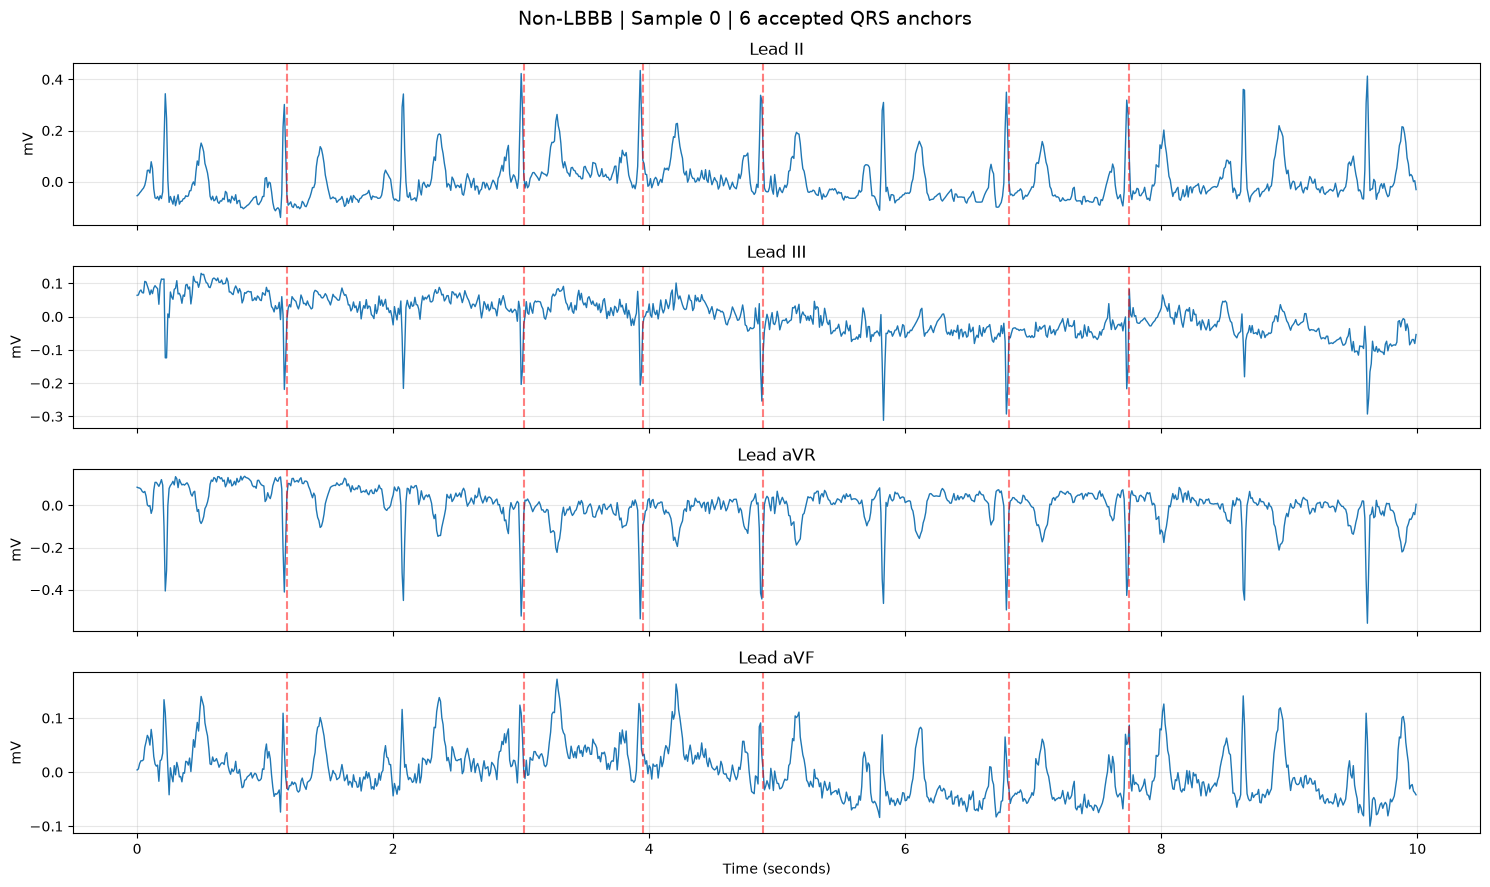

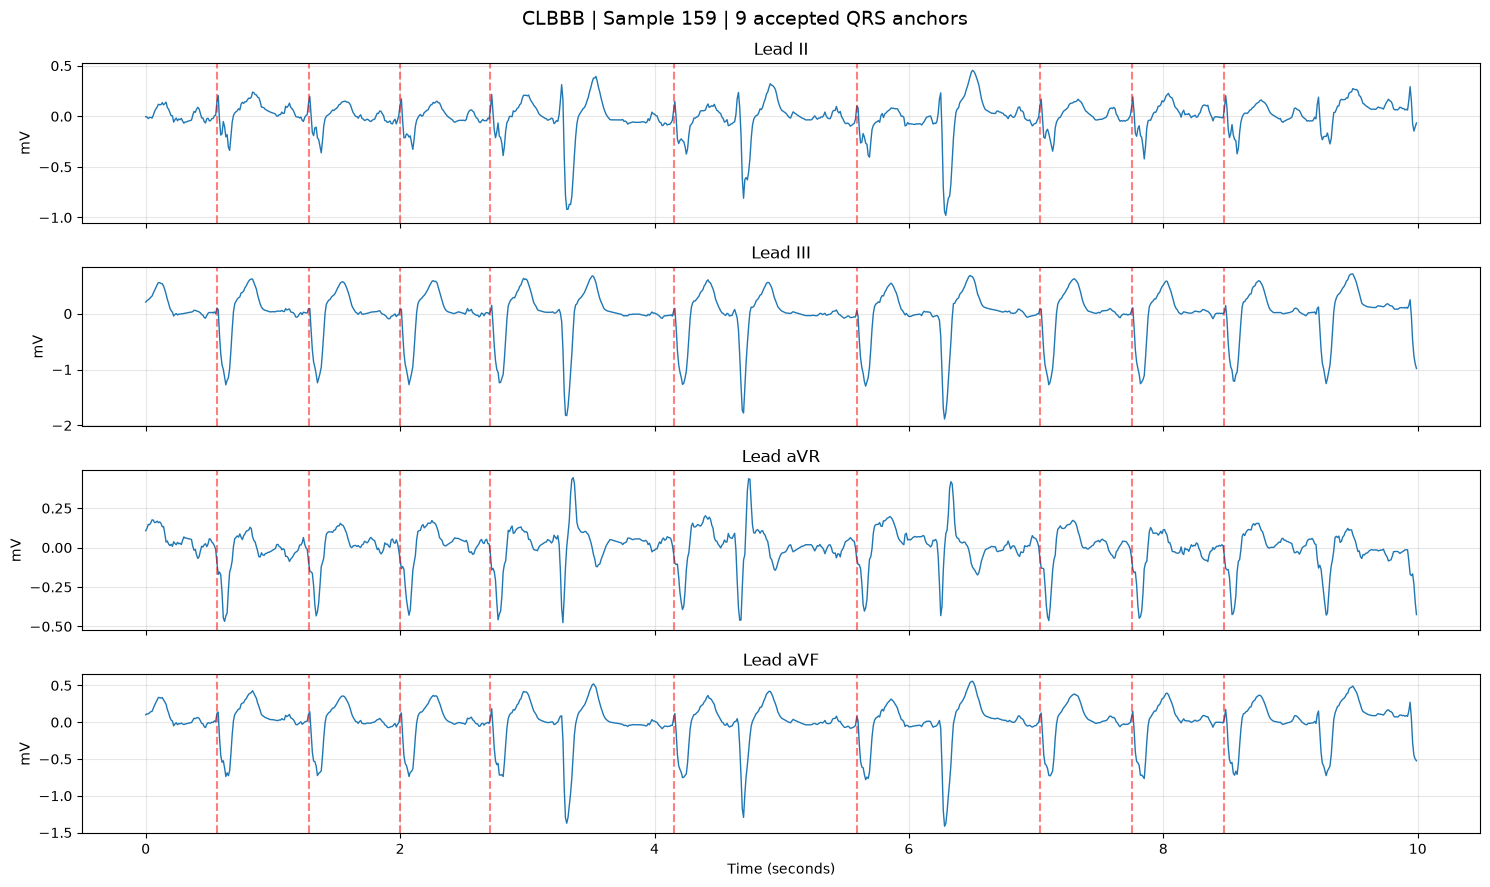

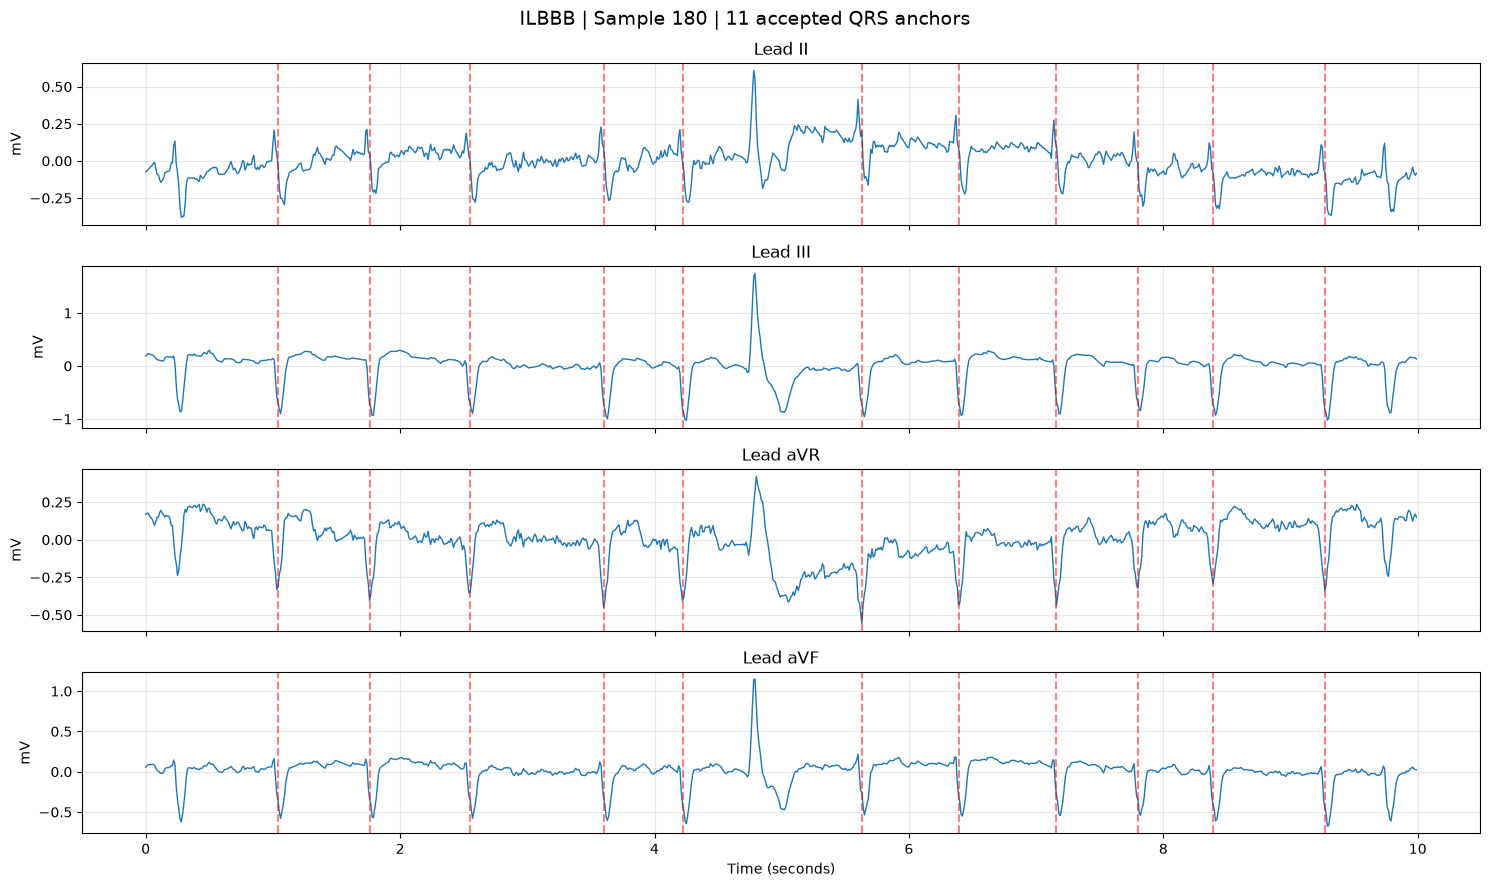

In [73]:
for category, example in extraction_examples.items():

    plot_detected_anchors(

        example,

        category

    )

In [74]:
def plot_median_beat(example, category):

    median = example["median"]

    windows = example["windows"]

    time_ms = (

        np.arange(MEDIAN_LENGTH) - PRE

    ) / MEDIAN_FS * 1000

    fig, axes = plt.subplots(

        2, 2,

        figsize=(14, 9),

        sharex=True

    )

    for ax, lead in zip(

        axes.ravel(),

        TARGET_LEADS

    ):

        idx = LEAD_INDICES[lead]

        # Plot individual accepted beats
        for i, beat in enumerate(windows):

            ax.plot(

                time_ms,

                beat[idx],

                color="gray",

                alpha=0.35,

                linewidth=0.9,

                label=(
                    "Individual beats"
                    if i == 0 else None
                )

            )

        # Plot final median
        ax.plot(

            time_ms,

            median[idx],

            color="blue",

            linewidth=2,

            label="Median beat"

        )

        ax.axvline(

            0,

            color="red",

            linestyle="--",

            alpha=0.6,

            label="QRS anchor"

        )

        ax.set_title(f"Lead {lead}")

        ax.set_xlabel("Time (ms)")

        ax.set_ylabel("Amplitude (mV)")

        ax.legend()

        ax.grid(alpha=0.3)

    fig.suptitle(

        f"{category} | "

        f"Sample {example['index']} | "

        f"{len(windows)} accepted beats",

        fontsize=15

    )

    plt.tight_layout()

    plt.show()

    plt.close(fig)

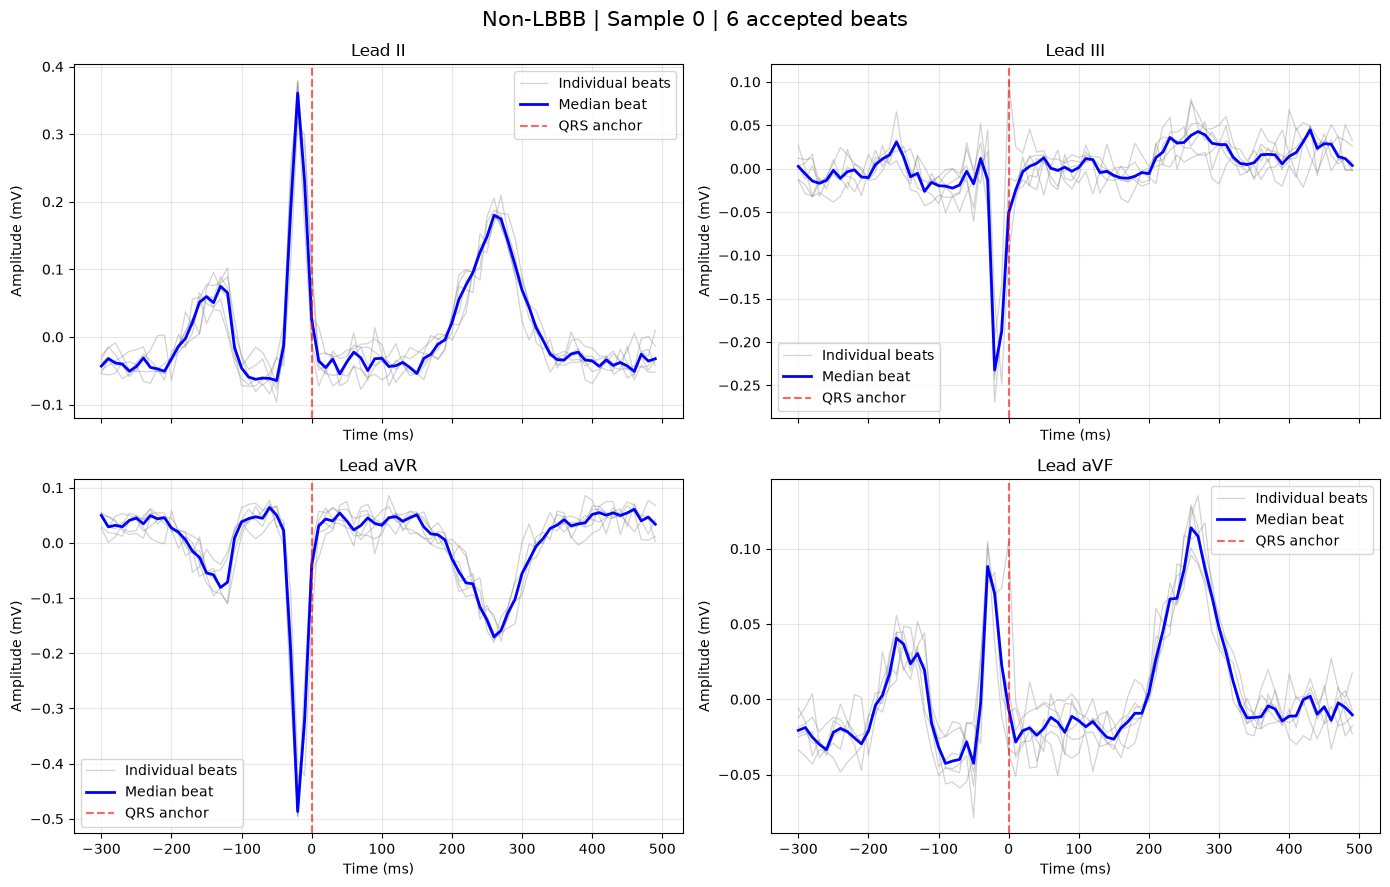

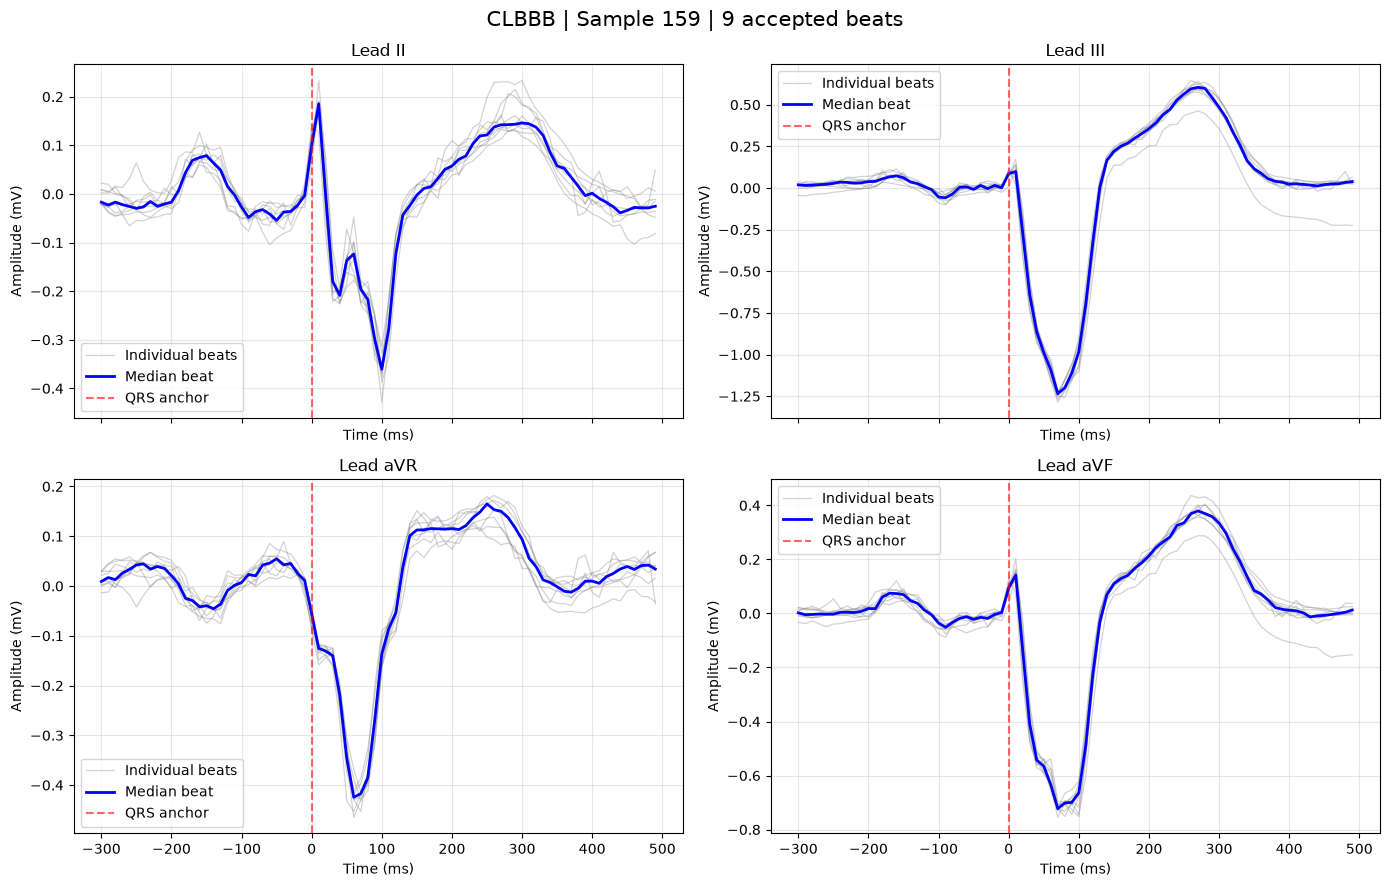

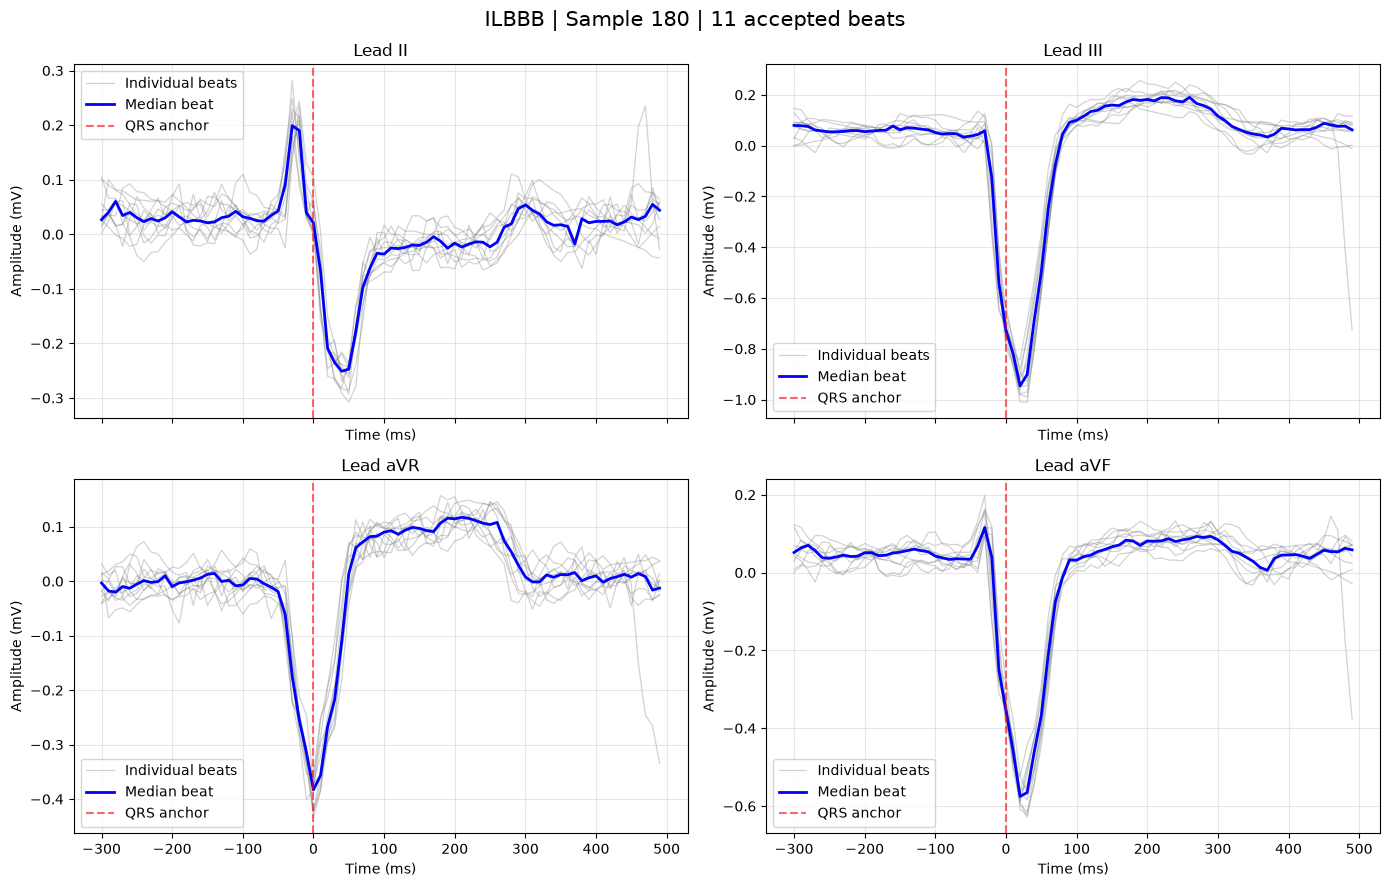

In [75]:
for category, example in extraction_examples.items():

    plot_median_beat(

        example,

        category

    )

### 10.10. Construct Median-Beat Dataset

Apply the adapted 100 Hz median-beat extraction
algorithm to all Dataset 2 recordings.

- Preserve original train, validation, and test splits.
- Maintain CLBBB and ILBBB label alignment.
- Record original array indices.
- Document rejected recordings and rejection reasons.
- Save median-beat arrays separately from full ECG arrays.

In [76]:
def construct_median_dataset(X, y, split):

    median_beats = []
    median_labels = []
    accepted_indices = []
    metadata = []

    start_time = time.perf_counter()

    n_samples = len(X)

    print(f"Processing {split.upper()}: {n_samples:,} recordings")

    for idx in range(n_samples):

        wave = X[idx]

        label = np.asarray(y[idx])

        try:

            median, anchors, windows = (
                extract_median_beat(wave)
            )

            metadata.append({
                "original_index": idx,
                "median_index": len(median_beats),
                "CLBBB": int(label[0]),
                "ILBBB": int(label[1]),
                "accepted_beats": len(anchors),
                "status": "accepted"
            })

            median_beats.append(median)
            median_labels.append(label.copy())
            accepted_indices.append(idx)

        except ValueError as e:

            metadata.append({
                "original_index": idx,
                "median_index": -1,
                "CLBBB": int(label[0]),
                "ILBBB": int(label[1]),
                "accepted_beats": 0,
                "status": str(e)
            })

        if (idx + 1) % 2000 == 0 or idx + 1 == n_samples:

            print(
                f"  Processed: {idx + 1:,}/{n_samples:,} | "
                f"Accepted: {len(median_beats):,} | "
                f"Rejected: {idx + 1 - len(median_beats):,}"
            )

    if not median_beats:

        raise RuntimeError(
            f"No accepted recordings in {split}"
        )

    X_median = np.stack(
        median_beats
    ).astype(np.float32)

    y_median = np.stack(
        median_labels
    ).astype(np.float32)

    accepted_indices = np.asarray(
        accepted_indices,
        dtype=np.int64
    )

    metadata_df = pd.DataFrame(metadata)

    # Verify dimensions and label alignment
    assert X_median.shape[1:] == (12, 80)

    assert y_median.shape == (
        len(X_median), 2
    )

    np.testing.assert_array_equal(
        y_median,
        y[accepted_indices]
    )

    assert np.isfinite(X_median).all()

    # Save arrays
    np.save(
        MEDIAN_DATA_DIR / f"X_{split}.npy",
        X_median
    )

    np.save(
        MEDIAN_DATA_DIR / f"y_{split}.npy",
        y_median
    )

    np.save(
        MEDIAN_DATA_DIR / f"indices_{split}.npy",
        accepted_indices
    )

    metadata_df.to_csv(
        MEDIAN_DATA_DIR / f"{split}_metadata.csv",
        index=False
    )

    elapsed = time.perf_counter() - start_time

    summary = {
        "split": split,
        "original_samples": n_samples,
        "accepted_samples": len(X_median),
        "rejected_samples": n_samples - len(X_median),
        "acceptance_rate": len(X_median) / n_samples,
        "processing_time_seconds": elapsed
    }

    print(f"\n{split.upper()} completed.")
    print(f"Median ECG shape: {X_median.shape}")
    print(f"Label shape: {y_median.shape}")
    print(f"Processing time: {elapsed:.2f} seconds\n")

    return summary

In [77]:
median_preprocessing_summaries = []

for split, (X, y) in datasets.items():

    summary = construct_median_dataset(
        X,
        y,
        split
    )

    median_preprocessing_summaries.append(
        summary
    )

median_preprocessing_summary = pd.DataFrame(
    median_preprocessing_summaries
)

median_preprocessing_summary.to_csv(
    MEDIAN_DATA_DIR / "preprocessing_summary.csv",
    index=False
)

display(
    median_preprocessing_summary.round(4)
)

Processing TRAIN: 17,418 recordings
  Processed: 2,000/17,418 | Accepted: 2,000 | Rejected: 0
  Processed: 4,000/17,418 | Accepted: 4,000 | Rejected: 0
  Processed: 6,000/17,418 | Accepted: 6,000 | Rejected: 0
  Processed: 8,000/17,418 | Accepted: 8,000 | Rejected: 0
  Processed: 10,000/17,418 | Accepted: 10,000 | Rejected: 0
  Processed: 12,000/17,418 | Accepted: 12,000 | Rejected: 0
  Processed: 14,000/17,418 | Accepted: 14,000 | Rejected: 0
  Processed: 16,000/17,418 | Accepted: 16,000 | Rejected: 0
  Processed: 17,418/17,418 | Accepted: 17,418 | Rejected: 0

TRAIN completed.
Median ECG shape: (17418, 12, 80)
Label shape: (17418, 2)
Processing time: 19.16 seconds

Processing VAL: 2,183 recordings
  Processed: 2,000/2,183 | Accepted: 2,000 | Rejected: 0
  Processed: 2,183/2,183 | Accepted: 2,183 | Rejected: 0

VAL completed.
Median ECG shape: (2183, 12, 80)
Label shape: (2183, 2)
Processing time: 2.35 seconds

Processing TEST: 2,198 recordings
  Processed: 2,000/2,198 | Accepted: 2,0

,split,original_samples,accepted_samples,rejected_samples,acceptance_rate,processing_time_seconds
0,train,17418,17418,0,1.0,19.1650
1,val,2183,2183,0,1.0,2.3516
2,test,2198,2198,0,1.0,2.4117


In [78]:
X_median_train = np.load(
    MEDIAN_DATA_DIR / "X_train.npy",
    mmap_mode="r"
)

X_median_val = np.load(
    MEDIAN_DATA_DIR / "X_val.npy",
    mmap_mode="r"
)

X_median_test = np.load(
    MEDIAN_DATA_DIR / "X_test.npy",
    mmap_mode="r"
)

y_median_train = np.load(
    MEDIAN_DATA_DIR / "y_train.npy",
    mmap_mode="r"
)

y_median_val = np.load(
    MEDIAN_DATA_DIR / "y_val.npy",
    mmap_mode="r"
)

y_median_test = np.load(
    MEDIAN_DATA_DIR / "y_test.npy",
    mmap_mode="r"
)

median_datasets = {
    "train": (X_median_train, y_median_train),
    "val": (X_median_val, y_median_val),
    "test": (X_median_test, y_median_test)
}

for split, (X, y) in median_datasets.items():

    assert X.shape[1:] == (12, 80)
    assert y.shape == (len(X), 2)
    assert np.isin(y, [0, 1]).all()

    print(f"{split.upper()}")
    print(f"  X shape: {X.shape}")
    print(f"  y shape: {y.shape}")
    print()

TRAIN
  X shape: (17418, 12, 80)
  y shape: (17418, 2)

VAL
  X shape: (2183, 12, 80)
  y shape: (2183, 2)

TEST
  X shape: (2198, 12, 80)
  y shape: (2198, 2)



In [79]:
rejection_summaries = []

for split in ["train", "val", "test"]:

    metadata = pd.read_csv(
        MEDIAN_DATA_DIR / f"{split}_metadata.csv"
    )

    rejected = metadata[
        metadata["status"] != "accepted"
    ]

    print(f"\n{split.upper()}")

    print(
        metadata["status"].value_counts()
    )

    rejection_summaries.append({

        "Split": split,

        "Rejected recordings": len(rejected),

        "Rejected CLBBB positives": int(
            rejected["CLBBB"].sum()
        ),

        "Rejected ILBBB positives": int(
            rejected["ILBBB"].sum()
        )

    })

rejection_summary = pd.DataFrame(
    rejection_summaries
)

display(rejection_summary)

rejection_summary.to_csv(
    MEDIAN_DATA_DIR / "rejection_summary.csv",
    index=False
)


TRAIN
status
accepted    17418
Name: count, dtype: int64

VAL
status
accepted    2183
Name: count, dtype: int64

TEST
status
accepted    2198
Name: count, dtype: int64


,Split,Rejected recordings,Rejected CLBBB positives,Rejected ILBBB positives
0,train,0,0,0
1,val,0,0,0
2,test,0,0,0


In [80]:
distribution_comparison = []

for split in ["train", "val", "test"]:

    _, original_y = datasets[split]

    _, median_y = median_datasets[split]

    for i, label in enumerate(LABELS):

        original_positive = int(
            original_y[:, i].sum()
        )

        median_positive = int(
            median_y[:, i].sum()
        )

        distribution_comparison.append({

            "Split": split,

            "Label": label,

            "Original Total": len(original_y),

            "Median Total": len(median_y),

            "Original Positives": original_positive,

            "Median Positives": median_positive,

            "Lost Positives": (
                original_positive - median_positive
            ),

            "Original Prevalence (%)": (
                original_positive / len(original_y) * 100
            ),

            "Median Prevalence (%)": (
                median_positive / len(median_y) * 100
            )

        })

median_distribution_comparison = pd.DataFrame(
    distribution_comparison
)

display(
    median_distribution_comparison.round(4)
)

,Split,Label,Original Total,Median Total,Original Positives,Median Positives,Lost Positives,Original Prevalence (%),Median Prevalence (%)
0,train,CLBBB,17418,17418,428,428,0,2.4572,2.4572
1,train,ILBBB,17418,17418,62,62,0,0.3560,0.3560
2,val,CLBBB,2183,2183,54,54,0,2.4737,2.4737
3,val,ILBBB,2183,2183,7,7,0,0.3207,0.3207
4,test,CLBBB,2198,2198,54,54,0,2.4568,2.4568
5,test,ILBBB,2198,2198,8,8,0,0.3640,0.3640


In [81]:
def create_dataloaders(
    lead,
    batch_size=BATCH_SIZE,
    representation="full_ecg"
):

    if representation == "full_ecg":

        selected_datasets = datasets

    elif representation == "median_beat":

        selected_datasets = median_datasets

    else:

        raise ValueError(
            f"Invalid representation: {representation}"
        )

    train_dataset = SingleLeadDataset(
        *selected_datasets["train"],
        lead=lead
    )

    val_dataset = SingleLeadDataset(
        *selected_datasets["val"],
        lead=lead
    )

    test_dataset = SingleLeadDataset(
        *selected_datasets["test"],
        lead=lead
    )

    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return train_loader, val_loader, test_loader

In [82]:
for lead in TARGET_LEADS:

    train_loader, val_loader, test_loader = (
        create_dataloaders(
            lead=lead,
            representation="median_beat"
        )
    )

    X_batch, y_batch = next(
        iter(train_loader)
    )

    assert X_batch.shape == (
        BATCH_SIZE, 1, 80
    )

    assert y_batch.shape == (
        BATCH_SIZE, 2
    )

    assert torch.isfinite(X_batch).all()

    print(f"Lead: {lead}")
    print(f"  Input shape: {X_batch.shape}")
    print(f"  Target shape: {y_batch.shape}")
    print(f"  Training batches: {len(train_loader)}")
    print()

Lead: II
  Input shape: torch.Size([32, 1, 80])
  Target shape: torch.Size([32, 2])
  Training batches: 545

Lead: III
  Input shape: torch.Size([32, 1, 80])
  Target shape: torch.Size([32, 2])
  Training batches: 545

Lead: aVR
  Input shape: torch.Size([32, 1, 80])
  Target shape: torch.Size([32, 2])
  Training batches: 545

Lead: aVF
  Input shape: torch.Size([32, 1, 80])
  Target shape: torch.Size([32, 2])
  Training batches: 545



In [83]:
median_model_tests = []

for architecture in ARCHITECTURES:

    set_seed(SEED)

    model = build_model(
        architecture
    ).to(device)

    model.train()

    train_loader, _, _ = create_dataloaders(
        lead="II",
        representation="median_beat"
    )

    X_batch, y_batch = next(
        iter(train_loader)
    )

    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device)

    median_pos_weights = calculate_pos_weights(
        y_median_train
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=median_pos_weights.to(device)
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    optimizer.zero_grad()

    logits = model(X_batch)

    loss = criterion(logits, y_batch)

    loss.backward()

    optimizer.step()

    synchronize_device(device)

    assert logits.shape == (BATCH_SIZE, 2)

    assert torch.isfinite(logits).all()

    assert torch.isfinite(loss).item()

    for param in model.parameters():

        if param.grad is not None:

            assert torch.isfinite(param.grad).all().item()

        assert torch.isfinite(param).all().item()

    median_model_tests.append({

        "Architecture": architecture,

        "Input Shape": str(tuple(X_batch.shape)),

        "Output Shape": str(tuple(logits.shape)),

        "Loss": loss.item(),

        "Device": str(device),

        "Status": "Passed"

    })

    del model, optimizer, criterion
    del X_batch, y_batch, logits, loss

    if device.type == "mps":

        torch.mps.empty_cache()

display(
    pd.DataFrame(median_model_tests)
)

,Architecture,Input Shape,Output Shape,Loss,Device,Status
0,baseline,"(32, 1, 80)","(32, 2)",0.612297,mps,Passed
1,improved,"(32, 1, 80)","(32, 2)",0.723940,mps,Passed


In [86]:
median_baseline_II_history, median_baseline_II_summary = (
    train_model(

        architecture="baseline",

        lead="II",

        representation="median_beat",

        max_epochs=MAX_EPOCHS,

        patience=PATIENCE,

        learning_rate=LEARNING_RATE,

        batch_size=BATCH_SIZE,

        seed=SEED

    )
)

display(
    median_baseline_II_summary.round(4)
)

Architecture: baseline
Lead: II
Device: mps
Parameters: 242,114
Results: results/experiment3/median_beat/baseline/II
Epoch 01/30 | Train: 0.7381 | Val: 0.9431 | Time: 6.8s
  CLBBB AUROC: 0.9423 | AUPRC: 0.2269
  ILBBB AUROC: 0.7549 | AUPRC: 0.0247
  Saved new best model
Epoch 02/30 | Train: 0.6502 | Val: 0.7440 | Time: 4.9s
  CLBBB AUROC: 0.9791 | AUPRC: 0.6138
  ILBBB AUROC: 0.8352 | AUPRC: 0.0782
  Saved new best model
Epoch 03/30 | Train: 0.5835 | Val: 0.7323 | Time: 5.1s
  CLBBB AUROC: 0.9734 | AUPRC: 0.4724
  ILBBB AUROC: 0.8523 | AUPRC: 0.0921
  Saved new best model
Epoch 04/30 | Train: 0.5192 | Val: 0.7410 | Time: 4.8s
  CLBBB AUROC: 0.9730 | AUPRC: 0.4711
  ILBBB AUROC: 0.8332 | AUPRC: 0.0409
  No improvement: 1/7
Epoch 05/30 | Train: 0.5077 | Val: 0.7841 | Time: 4.9s
  CLBBB AUROC: 0.9787 | AUPRC: 0.5930
  ILBBB AUROC: 0.8333 | AUPRC: 0.0754
  No improvement: 2/7
Epoch 06/30 | Train: 0.4717 | Val: 0.9613 | Time: 4.8s
  CLBBB AUROC: 0.9804 | AUPRC: 0.6226
  ILBBB AUROC: 0.8104 

,architecture,lead,representation,best_epoch,epochs_trained,best_val_loss,CLBBB_AUROC,CLBBB_AUPRC,ILBBB_AUROC,ILBBB_AUPRC,training_time_seconds
0,baseline,II,full_ecg,3,10,0.7323,0.9734,0.4724,0.8523,0.0921,51.6327


In [87]:
all_median_training_summaries = []

start_time = time.perf_counter()

for architecture in ARCHITECTURES:

    for lead in TARGET_LEADS:

        run_dir = get_run_directory(
            architecture,
            lead,
            representation="median_beat"
        )

        required_files = [
            "best_model.pt",
            "config.json",
            "training_history.csv",
            "validation_metrics.csv",
            "validation_scores.npy",
            "validation_targets.npy"
        ]

        completed = all(
            (run_dir / filename).exists()
            for filename in required_files
        )

        if completed:

            print(
                f"Skipping completed model: "
                f"{architecture} | Lead {lead}"
            )

            summary_df = pd.read_csv(
                run_dir / "validation_metrics.csv"
            )

        else:

            history_df, summary_df = train_model(

                architecture=architecture,

                lead=lead,

                representation="median_beat",

                max_epochs=MAX_EPOCHS,

                patience=PATIENCE,

                learning_rate=LEARNING_RATE,

                batch_size=BATCH_SIZE,

                seed=SEED

            )

        all_median_training_summaries.append(
            summary_df
        )

median_validation_results = pd.concat(
    all_median_training_summaries,
    ignore_index=True
)

assert len(median_validation_results) == 8

assert (
    median_validation_results["representation"]
    == "median_beat"
).all()

assert not median_validation_results.duplicated(
    subset=["architecture", "lead"]
).any()

MEDIAN_RESULTS_DIR = RESULTS_DIR / "median_beat"

median_validation_results.to_csv(
    MEDIAN_RESULTS_DIR / "all_validation_results.csv",
    index=False
)

elapsed_time = time.perf_counter() - start_time

print(
    f"\nTraining session completed in "
    f"{elapsed_time / 60:.2f} minutes."
)

display(
    median_validation_results.round(4)
)

Skipping completed model: baseline | Lead II
Architecture: baseline
Lead: III
Device: mps
Parameters: 242,114
Results: results/experiment3/median_beat/baseline/III
Epoch 01/30 | Train: 1.0004 | Val: 0.8980 | Time: 6.8s
  CLBBB AUROC: 0.9284 | AUPRC: 0.2639
  ILBBB AUROC: 0.8080 | AUPRC: 0.0126
  Saved new best model
Epoch 02/30 | Train: 0.9016 | Val: 0.7741 | Time: 5.0s
  CLBBB AUROC: 0.9466 | AUPRC: 0.2939
  ILBBB AUROC: 0.8405 | AUPRC: 0.0388
  Saved new best model
Epoch 03/30 | Train: 0.7800 | Val: 0.7571 | Time: 4.8s
  CLBBB AUROC: 0.9575 | AUPRC: 0.3381
  ILBBB AUROC: 0.8747 | AUPRC: 0.0236
  Saved new best model
Epoch 04/30 | Train: 0.7450 | Val: 0.7147 | Time: 4.8s
  CLBBB AUROC: 0.9548 | AUPRC: 0.3658
  ILBBB AUROC: 0.8667 | AUPRC: 0.0288
  Saved new best model
Epoch 05/30 | Train: 0.6947 | Val: 0.6910 | Time: 4.9s
  CLBBB AUROC: 0.9638 | AUPRC: 0.4177
  ILBBB AUROC: 0.8867 | AUPRC: 0.0338
  Saved new best model
Epoch 06/30 | Train: 0.6690 | Val: 0.6879 | Time: 6.1s
  CLBBB AUR

AssertionError: 